In [ ]:
#cell 1
# Set up the project environment and load the AURA dataset

from pathlib import Path
import random
import json

import cv2
import numpy as np
import pandas as pd

from google.colab import drive

# Connect Google Drive
drive.mount("/content/drive")

# Define project directories
PROJECT_DIR = Path("/content/drive/MyDrive/CAI421_Project")

DATA_DIR = PROJECT_DIR / "AURA" / "AURA"
ANNOTATIONS_DIR = DATA_DIR / "annotations"

REPORTS_DIR = PROJECT_DIR / "reports"
SPLITS_DIR = PROJECT_DIR / "splits"

REPORTS_DIR.mkdir(parents=True, exist_ok=True)
SPLITS_DIR.mkdir(parents=True, exist_ok=True)

# Set random seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Define the dataset scenes
SCENES = {
    "Scene_A": DATA_DIR / "scene_A",
    "Scene_B": DATA_DIR / "scene_B"
}

# Check the required dataset files
required_paths = [
    DATA_DIR / "README.md",
    ANNOTATIONS_DIR / "soft_labels.csv",
    ANNOTATIONS_DIR / "consensus_events.csv",
    SCENES["Scene_A"] / "normal_frames.csv",
    SCENES["Scene_A"] / "test_frames.csv",
    SCENES["Scene_A"] / "videos",
    SCENES["Scene_B"] / "normal_frames.csv",
    SCENES["Scene_B"] / "test_frames.csv",
    SCENES["Scene_B"] / "videos"
]

missing_paths = [
    str(path) for path in required_paths
    if not path.exists()
]

if missing_paths:
    raise FileNotFoundError(
        "Missing dataset paths:\n" + "\n".join(missing_paths)
    )

# Load annotation files
soft_labels = pd.read_csv(
    ANNOTATIONS_DIR / "soft_labels.csv"
)

consensus_events = pd.read_csv(
    ANNOTATIONS_DIR / "consensus_events.csv"
)

normal_frames = {}
test_frames = {}

for scene in ["A", "B"]:
    scene_dir = DATA_DIR / f"scene_{scene}"

    normal_frames[scene] = pd.read_csv(
        scene_dir / "normal_frames.csv"
    )

    test_frames[scene] = pd.read_csv(
        scene_dir / "test_frames.csv"
    )

# Validate the required columns
for scene in ["A", "B"]:
    if not {"video", "frame_idx"}.issubset(
        normal_frames[scene].columns
    ):
        raise ValueError(
            f"Invalid normal_frames.csv columns in Scene {scene}"
        )

    if not {"video", "frame_idx", "label"}.issubset(
        test_frames[scene].columns
    ):
        raise ValueError(
            f"Invalid test_frames.csv columns in Scene {scene}"
        )

if not {
    "scene", "video", "frame_idx", "soft_label"
}.issubset(soft_labels.columns):
    raise ValueError("Invalid soft_labels.csv columns.")

print("Dataset loaded successfully.")
print("Random seed:", SEED)
print("Soft-label records:", len(soft_labels))
print("Consensus events:", len(consensus_events))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset loaded successfully.
Random seed: 42
Soft-label records: 11709
Consensus events: 25


In [ ]:
# cell 2
# Inspect videos and document dataset characteristics

video_records = []

expected_video_counts = {
    "Scene_A": 10,
    "Scene_B": 15
}

for scene_name, scene_dir in SCENES.items():

    video_dir = scene_dir / "videos"
    video_paths = sorted(video_dir.glob("*.mp4"))

    if len(video_paths) != expected_video_counts[scene_name]:
        raise ValueError(
            f"Unexpected video count in {scene_name}: "
            f"{len(video_paths)}"
        )

    for video_path in video_paths:

        cap = cv2.VideoCapture(str(video_path))

        if not cap.isOpened():
            raise ValueError(
                f"Could not open video: {video_path.name}"
            )

        frame_count = int(
            cap.get(cv2.CAP_PROP_FRAME_COUNT)
        )

        fps = float(
            cap.get(cv2.CAP_PROP_FPS)
        )

        width = int(
            cap.get(cv2.CAP_PROP_FRAME_WIDTH)
        )

        height = int(
            cap.get(cv2.CAP_PROP_FRAME_HEIGHT)
        )

        cap.release()

        if frame_count <= 0 or not np.isfinite(fps) or fps <= 0:
            raise ValueError(
                f"Invalid video properties: {video_path.name}"
            )

        if width <= 0 or height <= 0:
            raise ValueError(
                f"Invalid resolution: {video_path.name}"
            )

        video_records.append({
            "scene": scene_name,
            "video": video_path.stem,
            "video_path": str(video_path),
            "frame_count": frame_count,
            "fps": fps,
            "width": width,
            "height": height,
            "resolution": f"{width}x{height}",
            "duration_sec": frame_count / fps,
            "size_mb": video_path.stat().st_size / (1024 ** 2)
        })

# Create the video inventory
inventory = pd.DataFrame(video_records)

if inventory.duplicated(
    subset=["scene", "video"]
).any():
    raise ValueError("Duplicate video identifiers were found.")

if len(inventory) != 25:
    raise ValueError(
        f"Expected 25 videos, found {len(inventory)}."
    )

# Save the detailed inventory
inventory.to_csv(
    REPORTS_DIR / "dataset_inventory.csv",
    index=False
)

# Summarize the dataset by scene
dataset_summary = inventory.groupby("scene").agg(
    video_count=("video", "nunique"),
    total_frames=("frame_count", "sum"),
    average_fps=("fps", "mean"),
    average_width=("width", "mean"),
    average_height=("height", "mean"),
    total_duration_sec=("duration_sec", "sum"),
    total_size_mb=("size_mb", "sum")
).reset_index()

dataset_summary.to_csv(
    REPORTS_DIR / "dataset_summary.csv",
    index=False
)

print("Dataset summary:")
display(dataset_summary.round(2))

print("\nVideo inventory:")
display(
    inventory[
        [
            "scene", "video", "frame_count", "fps",
            "resolution", "duration_sec", "size_mb"
        ]
    ].round(2)
)

print("\nTotal videos:", inventory["video"].nunique())
print("Total frames:", inventory["frame_count"].sum())

Dataset summary:


,scene,video_count,total_frames,average_fps,average_width,average_height,total_duration_sec,total_size_mb
0,Scene_A,10,12524,30.0,1920.0,1080.0,417.47,407.06
1,Scene_B,15,2559,15.0,1920.0,1080.0,170.60,31.04



Video inventory:


,scene,video,frame_count,fps,resolution,duration_sec,size_mb
0,Scene_A,v00,1309,30.0,1920x1080,43.63,34.31
1,Scene_A,v01,1303,30.0,1920x1080,43.43,45.94
2,Scene_A,v02,1507,30.0,1920x1080,50.23,36.24
3,Scene_A,v03,797,30.0,1920x1080,26.57,28.30
4,Scene_A,v04,1586,30.0,1920x1080,52.87,55.47
5,Scene_A,v05,1551,30.0,1920x1080,51.70,54.57
6,Scene_A,v06,531,30.0,1920x1080,17.70,16.75
7,Scene_A,v07,1382,30.0,1920x1080,46.07,53.89
8,Scene_A,v08,1061,30.0,1920x1080,35.37,36.33
9,Scene_A,v09,1497,30.0,1920x1080,49.90,45.26



Total videos: 25
Total frames: 15083


In [ ]:
# Cell 3: Analyze label distribution and annotation quality

def normalize_scene(value):
    value = str(value).strip().lower()

    if value in {"a", "scene_a", "scene a"}:
        return "Scene_A"
    if value in {"b", "scene_b", "scene b"}:
        return "Scene_B"
    raise ValueError(f"Unknown scene name: {value}")


soft_labels["scene"] = soft_labels["scene"].apply(normalize_scene)

for scene in ["A", "B"]:
    normal_frames[scene]["scene"] = f"Scene_{scene}"
    test_frames[scene]["scene"] = f"Scene_{scene}"

# Keep the original test-label values visible instead of assuming labels are 0/1.
label_records = []
raw_test_label_records = []

for scene in ["A", "B"]:
    normal_df = normal_frames[scene]
    test_df = test_frames[scene]

    label_records.append({
        "scene": f"Scene_{scene}",
        "normal_training_frames": len(normal_df),
        "training_videos": normal_df["video"].astype(str).nunique(),
        "test_frames": len(test_df),
        "test_videos": test_df["video"].astype(str).nunique(),
        "test_label_missing": int(test_df["label"].isna().sum()),
        "unique_test_label_values": test_df["label"].dropna().astype(str).nunique()
    })

    value_counts = test_df["label"].astype("string").fillna("<MISSING>").value_counts()
    for label_value, count in value_counts.items():
        raw_test_label_records.append({
            "scene": f"Scene_{scene}",
            "test_label_value": str(label_value),
            "frame_count": int(count)
        })

label_distribution = pd.DataFrame(label_records)
raw_test_label_distribution = pd.DataFrame(raw_test_label_records)

print("Dataset frame counts and test-label availability:")
display(label_distribution)

print("\nActual values found in test_frames.csv label columns:")
display(raw_test_label_distribution)

label_distribution.to_csv(REPORTS_DIR / "label_distribution.csv", index=False)
raw_test_label_distribution.to_csv(
    REPORTS_DIR / "raw_test_label_distribution.csv", index=False
)

# Validate soft-label values and annotation records.
required_soft_label_columns = {"scene", "video", "frame_idx", "soft_label"}
if not required_soft_label_columns.issubset(soft_labels.columns):
    raise ValueError("soft_labels.csv is missing required columns.")

soft_labels["video"] = soft_labels["video"].astype(str)
soft_labels["frame_idx"] = pd.to_numeric(soft_labels["frame_idx"], errors="coerce")
soft_labels["soft_label"] = pd.to_numeric(soft_labels["soft_label"], errors="coerce")

soft_label_quality = pd.DataFrame([{
    "total_records": len(soft_labels),
    "missing_values": int(
        soft_labels[["scene", "video", "frame_idx", "soft_label"]].isna().sum().sum()
    ),
    "duplicate_frame_records": int(
        soft_labels.duplicated(subset=["scene", "video", "frame_idx"]).sum()
    ),
    "invalid_soft_labels": int(
        (
            (soft_labels["soft_label"] < 0)
            | (soft_labels["soft_label"] > 1)
        ).fillna(False).sum()
    )
}])

display(soft_label_quality)
soft_label_quality.to_csv(REPORTS_DIR / "soft_label_quality.csv", index=False)

# Summarize soft labels without converting them to hard classes.
soft_label_summary = soft_labels.groupby("scene").agg(
    labeled_frames=("frame_idx", "count"),
    unique_videos=("video", "nunique"),
    mean_soft_label=("soft_label", "mean"),
    median_soft_label=("soft_label", "median"),
    minimum_soft_label=("soft_label", "min"),
    maximum_soft_label=("soft_label", "max")
).reset_index()

soft_label_summary.to_csv(
    REPORTS_DIR / "soft_label_summary_by_scene.csv", index=False
)
print("\nSoft-label summary by scene:")
display(soft_label_summary.round(4))

# Calculate label coverage for each video.
label_coverage = soft_labels.groupby(["scene", "video"]).agg(
    labeled_frames=("frame_idx", "nunique"),
    mean_soft_label=("soft_label", "mean")
).reset_index()

label_coverage = inventory[["scene", "video", "frame_count"]].copy()
label_coverage["video"] = label_coverage["video"].astype(str)
label_coverage = label_coverage.merge(
    soft_labels.groupby(["scene", "video"]).agg(
        labeled_frames=("frame_idx", "nunique"),
        mean_soft_label=("soft_label", "mean")
    ).reset_index(),
    on=["scene", "video"],
    how="left"
)

label_coverage["labeled_frames"] = (
    label_coverage["labeled_frames"].fillna(0).astype(int)
)
label_coverage["coverage_percent"] = (
    label_coverage["labeled_frames"] / label_coverage["frame_count"] * 100
)

label_coverage.to_csv(REPORTS_DIR / "label_coverage.csv", index=False)

soft_labels["soft_label"].describe().to_csv(
    REPORTS_DIR / "soft_label_statistics.csv", header=["value"]
)

print("\nSoft-label coverage by video:")
display(label_coverage.round(2))

print("\nAnnotation quality:")
display(soft_label_quality)

if soft_label_quality.loc[0, "missing_values"] > 0:
    raise ValueError("Missing values found in required soft-label fields.")
if soft_label_quality.loc[0, "duplicate_frame_records"] > 0:
    raise ValueError("Duplicate (scene, video, frame_idx) soft-label records found.")
if soft_label_quality.loc[0, "invalid_soft_labels"] > 0:
    raise ValueError("Soft labels must be within [0, 1].")


Dataset frame counts and test-label availability:


,scene,normal_training_frames,training_videos,test_frames,test_videos,test_label_missing,unique_test_label_values
0,Scene_A,6516,7,4277,3,0,2
1,Scene_B,844,10,954,5,0,2



Actual values found in test_frames.csv label columns:


,scene,test_label_value,frame_count
0,Scene_A,normal,3394
1,Scene_A,anomalous,883
2,Scene_B,anomalous,628
3,Scene_B,normal,326


,total_records,missing_values,duplicate_frame_records,invalid_soft_labels
0,11709,0,0,0



Soft-label summary by scene:


,scene,labeled_frames,unique_videos,mean_soft_label,median_soft_label,minimum_soft_label,maximum_soft_label
0,Scene_A,9506,10,0.3009,0.0625,0.0,1.0
1,Scene_B,2203,15,0.5715,0.8125,0.0,1.0



Soft-label coverage by video:


,scene,video,frame_count,labeled_frames,mean_soft_label,coverage_percent
0,Scene_A,v00,1309,438,0.44,33.46
1,Scene_A,v01,1303,1303,0.27,100.00
2,Scene_A,v02,1507,1507,0.08,100.00
3,Scene_A,v03,797,797,0.37,100.00
4,Scene_A,v04,1586,1470,0.42,92.69
5,Scene_A,v05,1551,518,0.16,33.40
6,Scene_A,v06,531,509,0.39,95.86
7,Scene_A,v07,1382,406,0.36,29.38
8,Scene_A,v08,1061,1061,0.46,100.00
9,Scene_A,v09,1497,1497,0.24,100.00



Annotation quality:


,total_records,missing_values,duplicate_frame_records,invalid_soft_labels
0,11709,0,0,0


In [ ]:
#cell 4 Prepare video frames, temporal sequences, augmentation, and data splits

IMAGE_SIZE = (224, 224)
SEQUENCE_LENGTH = 16

PREPROCESSING_CONFIG = {
    "image_width": IMAGE_SIZE[0],
    "image_height": IMAGE_SIZE[1],
    "color_format": "RGB",
    "pixel_range": [0.0, 1.0],
    "sequence_length": SEQUENCE_LENGTH,
    "random_seed": SEED,
    "augmentation": {
        "training_only": True,
        "horizontal_flip": False,
        "brightness_range": [0.9, 1.1],
        "contrast_range": [0.9, 1.1]
    }
}

# Preprocess a single frame
def preprocess_frame(video_path, frame_idx):
    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        raise ValueError(f"Could not open video: {video_path}")

    cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_idx))
    success, frame = cap.read()
    cap.release()

    if not success:
        raise ValueError(
            f"Could not read frame {frame_idx} from {video_path}"
        )

    frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    frame = cv2.resize(
        frame,
        IMAGE_SIZE,
        interpolation=cv2.INTER_AREA
    )

    return frame.astype(np.float32) / 255.0


# Apply consistent brightness and contrast changes to a sequence
def augment_sequence(sequence, rng):
    brightness = rng.uniform(0.9, 1.1)
    contrast = rng.uniform(0.9, 1.1)

    # Use one set of parameters for the entire sequence
    sequence_mean = sequence.mean(axis=(1, 2), keepdims=True)

    augmented = (
        (sequence - sequence_mean) * contrast
        + sequence_mean
    )

    augmented = augmented * brightness

    return np.clip(augmented, 0.0, 1.0).astype(np.float32)


# Read a video and create a fixed-length temporal sequence
def load_video_sequence(video_path, sequence_length=SEQUENCE_LENGTH,
                        augment=False, seed=SEED):

    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        raise ValueError(f"Could not open video: {video_path}")

    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.release()

    if frame_count <= 0:
        raise ValueError(f"Video has no readable frames: {video_path}")

    # Select frames evenly across the video
    frame_indices = np.linspace(
        0,
        frame_count - 1,
        num=min(sequence_length, frame_count),
        dtype=int
    )

    frames = [
        preprocess_frame(video_path, idx)
        for idx in frame_indices
    ]

    # Repeat the last frame if the video is shorter than the sequence
    while len(frames) < sequence_length:
        frames.append(frames[-1].copy())

    sequence = np.stack(frames, axis=0)

    if augment:
        rng = np.random.default_rng(seed)
        sequence = augment_sequence(sequence, rng)

    return sequence


# Smoke-test preprocessing and augmentation on one real video before creating manifests.
sample_video_row = inventory.iloc[0]
sample_video_path = Path(sample_video_row["video_path"])

sample_sequence = load_video_sequence(
    sample_video_path,
    sequence_length=SEQUENCE_LENGTH,
    augment=False
)
sample_augmented_sequence = load_video_sequence(
    sample_video_path,
    sequence_length=SEQUENCE_LENGTH,
    augment=True,
    seed=SEED
)

expected_shape = (
    SEQUENCE_LENGTH,
    IMAGE_SIZE[1],
    IMAGE_SIZE[0],
    3
)

if sample_sequence.shape != expected_shape:
    raise ValueError(
        f"Unexpected sequence shape: {sample_sequence.shape}; expected {expected_shape}"
    )
if sample_augmented_sequence.shape != expected_shape:
    raise ValueError("Augmented sequence has an unexpected shape.")
if not np.isfinite(sample_sequence).all():
    raise ValueError("Preprocessed sequence contains NaN or infinite values.")
if sample_sequence.min() < 0 or sample_sequence.max() > 1:
    raise ValueError("Preprocessed pixels must be within [0, 1].")
if not np.isfinite(sample_augmented_sequence).all():
    raise ValueError("Augmented sequence contains NaN or infinite values.")
if sample_augmented_sequence.min() < 0 or sample_augmented_sequence.max() > 1:
    raise ValueError("Augmented pixels must be within [0, 1].")

print("Preprocessing smoke test passed.")
print("Sample video:", sample_video_row["video"])
print("Sequence shape:", sample_sequence.shape)
print("Pixel range:", float(sample_sequence.min()), "to", float(sample_sequence.max()))
print("Augmentation test passed; augmentation is only enabled when augment=True.")

# Save preprocessing settings
with open(
    REPORTS_DIR / "preprocessing_config.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(PREPROCESSING_CONFIG, file, indent=4)


# Collect the video IDs from the original annotations
normal_video_ids = {
    scene: sorted(
        normal_frames[scene]["video"].astype(str).unique()
    )
    for scene in ["A", "B"]
}

original_test_ids = {
    scene: sorted(
        test_frames[scene]["video"].astype(str).unique()
    )
    for scene in ["A", "B"]
}

all_video_ids = {
    scene: sorted(
        inventory.loc[
            inventory["scene"] == f"Scene_{scene}", "video"
        ].astype(str).unique()
    )
    for scene in ["A", "B"]
}

# Verify the original training and test videos do not overlap
for scene in ["A", "B"]:
    overlap = (
        set(normal_video_ids[scene])
        & set(original_test_ids[scene])
    )

    if overlap:
        raise ValueError(
            f"Original training/test overlap in Scene {scene}: {overlap}"
        )


# Split training videos into training and validation groups
def split_videos(video_ids, seed=SEED):
    video_ids = sorted(set(video_ids))

    if len(video_ids) < 2:
        raise ValueError(
            "At least two videos are required for train/validation."
        )

    shuffled = video_ids.copy()
    random.Random(seed).shuffle(shuffled)

    validation_count = max(
        1, round(len(shuffled) * 0.20)
    )
    validation_count = min(
        validation_count, len(shuffled) - 1
    )

    validation_ids = sorted(shuffled[:validation_count])
    training_ids = sorted(shuffled[validation_count:])

    return training_ids, validation_ids


# Define the four experiments in the research methodology
experiments = {
    "A_to_A": ("A", "A", "within_scene"),
    "B_to_B": ("B", "B", "within_scene"),
    "A_to_B": ("A", "B", "cross_scene"),
    "B_to_A": ("B", "A", "cross_scene")
}

video_split_records = []
frame_split_records = []

for experiment, (source, target, mode) in experiments.items():

    train_ids, val_ids = split_videos(
        normal_video_ids[source],
        seed=SEED
    )

    if mode == "within_scene":
        test_ids = original_test_ids[target]
    else:
        test_ids = all_video_ids[target]

    # Ensure the video groups are mutually exclusive
    assert not set(train_ids) & set(val_ids)
    assert not set(train_ids) & set(test_ids)
    assert not set(val_ids) & set(test_ids)

    # Record video-level assignments
    for split_name, video_ids, scene in [
        ("train", train_ids, source),
        ("validation", val_ids, source),
        ("test", test_ids, target)
    ]:
        for video in video_ids:
            video_split_records.append({
                "experiment": experiment,
                "split": split_name,
                "scene": f"Scene_{scene}",
                "video": video
            })

    # Select training frames from normal training annotations
    train_df = normal_frames[source].copy()
    train_df["scene"] = f"Scene_{source}"
    train_df = train_df[
        train_df["video"].astype(str).isin(train_ids)
    ].copy()
    train_df["split"] = "train"

    # Select validation frames from separate videos
    val_df = normal_frames[source].copy()
    val_df["scene"] = f"Scene_{source}"
    val_df = val_df[
        val_df["video"].astype(str).isin(val_ids)
    ].copy()
    val_df["split"] = "validation"

    # Select test frames according to the evaluation protocol
    if mode == "within_scene":
        test_df = test_frames[target].copy()
        test_df["scene"] = f"Scene_{target}"
    else:
        test_df = soft_labels[
            soft_labels["scene"] == f"Scene_{target}"
        ].copy()

    test_df = test_df[
        test_df["video"].astype(str).isin(test_ids)
    ].copy()
    test_df["split"] = "test"

    for df in [train_df, val_df, test_df]:
        df["experiment"] = experiment

    frame_split_records.extend([
        train_df,
        val_df,
        test_df
    ])


# Combine split records
video_splits = pd.DataFrame(video_split_records)

frame_splits = pd.concat(
    frame_split_records,
    ignore_index=True,
    sort=False
)

# Save the complete split manifests
video_splits.to_csv(
    SPLITS_DIR / "video_splits.csv",
    index=False
)

frame_splits.to_csv(
    SPLITS_DIR / "frame_splits.csv",
    index=False
)

# Save separate files for each experiment and split
for experiment in experiments:
    for split_name in ["train", "validation", "test"]:

        subset = frame_splits[
            (frame_splits["experiment"] == experiment)
            & (frame_splits["split"] == split_name)
        ]

        subset.to_csv(
            SPLITS_DIR / f"{experiment}_{split_name}.csv",
            index=False
        )

print("Video-level split summary:")

display(
    video_splits.groupby(
        ["experiment", "split", "scene"]
    ).agg(
        video_count=("video", "nunique")
    ).reset_index()
)

print("\nFrame-level split summary:")

display(
    frame_splits.groupby(
        ["experiment", "split"]
    ).agg(
        frame_count=("frame_idx", "count"),
        video_count=("video", "nunique")
    ).reset_index()
)

# Report which test records have soft labels available.
test_rows = frame_splits[frame_splits["split"] == "test"].copy()
if "soft_label" in test_rows.columns:
    if "label" not in test_rows.columns:
        test_rows["label"] = np.nan
    test_rows["has_evaluation_label"] = (
        test_rows["soft_label"].notna() | test_rows["label"].notna()
    )
    test_label_coverage = test_rows.groupby("experiment").agg(
        test_records=("frame_idx", "count"),
        records_with_evaluation_label=("has_evaluation_label", "sum"),
        soft_label_records=("soft_label", "count"),
        hard_label_records=("label", "count"),
        test_videos=("video", "nunique")
    ).reset_index()
    test_label_coverage["label_coverage_percent"] = (
        test_label_coverage["records_with_evaluation_label"]
        / test_label_coverage["test_records"] * 100
    )
else:
    test_label_coverage = pd.DataFrame()

if not test_label_coverage.empty:
    test_label_coverage.to_csv(
        REPORTS_DIR / "test_split_label_coverage.csv", index=False
    )
    print("\nTest split label coverage:")
    display(test_label_coverage.round(2))

print("\nPreprocessing and splitting completed.")

Preprocessing smoke test passed.
Sample video: v00
Sequence shape: (16, 224, 224, 3)
Pixel range: 0.0 to 0.9529411792755127
Augmentation test passed; augmentation is only enabled when augment=True.
Video-level split summary:


,experiment,split,scene,video_count
0,A_to_A,test,Scene_A,3
1,A_to_A,train,Scene_A,6
2,A_to_A,validation,Scene_A,1
3,A_to_B,test,Scene_B,15
4,A_to_B,train,Scene_A,6
5,A_to_B,validation,Scene_A,1
6,B_to_A,test,Scene_A,10
7,B_to_A,train,Scene_B,8
8,B_to_A,validation,Scene_B,2
9,B_to_B,test,Scene_B,5



Frame-level split summary:


,experiment,split,frame_count,video_count
0,A_to_A,test,4277,3
1,A_to_A,train,5093,6
2,A_to_A,validation,1423,1
3,A_to_B,test,2203,15
4,A_to_B,train,5093,6
5,A_to_B,validation,1423,1
6,B_to_A,test,9506,10
7,B_to_A,train,713,8
8,B_to_A,validation,131,2
9,B_to_B,test,954,5



Test split label coverage:


,experiment,test_records,records_with_evaluation_label,soft_label_records,hard_label_records,test_videos,label_coverage_percent
0,A_to_A,4277,4277,0,4277,3,100.0
1,A_to_B,2203,2203,2203,0,15,100.0
2,B_to_A,9506,9506,9506,0,10,100.0
3,B_to_B,954,954,0,954,5,100.0



Preprocessing and splitting completed.


In [ ]:
#cell 5 Validate data splits and prepare the team handoff

leakage_records = []

for experiment in experiments:

    current = video_splits[
        video_splits["experiment"] == experiment
    ]

    train_ids = set(
        current.loc[current["split"] == "train", "video"]
    )

    val_ids = set(
        current.loc[current["split"] == "validation", "video"]
    )

    test_ids = set(
        current.loc[current["split"] == "test", "video"]
    )

    train_val_overlap = train_ids & val_ids
    train_test_overlap = train_ids & test_ids
    val_test_overlap = val_ids & test_ids

    current_frames = frame_splits[
        frame_splits["experiment"] == experiment
    ]

    frame_assignment_errors = 0

    for split_name, allowed_videos in [
        ("train", train_ids),
        ("validation", val_ids),
        ("test", test_ids)
    ]:
        subset = current_frames[
            current_frames["split"] == split_name
        ]

        invalid_rows = subset[
            ~subset["video"].astype(str).isin(allowed_videos)
        ]

        frame_assignment_errors += len(invalid_rows)

    leakage_records.append({
        "experiment": experiment,
        "train_videos": len(train_ids),
        "validation_videos": len(val_ids),
        "test_videos": len(test_ids),
        "train_validation_overlap": len(train_val_overlap),
        "train_test_overlap": len(train_test_overlap),
        "validation_test_overlap": len(val_test_overlap),
        "frame_assignment_errors": frame_assignment_errors,
        "passed": (
            len(train_val_overlap) == 0
            and len(train_test_overlap) == 0
            and len(val_test_overlap) == 0
            and frame_assignment_errors == 0
        )
    })

leakage_report = pd.DataFrame(leakage_records)

leakage_report.to_csv(
    REPORTS_DIR / "leakage_check.csv",
    index=False
)

print("Leakage validation:")
display(leakage_report)

if not leakage_report["passed"].all():
    raise ValueError(
        "Split validation failed. Review leakage_check.csv."
    )


# Check that no identical frame record is assigned more than once per experiment.
duplicate_frame_rows = frame_splits.duplicated(
    subset=["experiment", "scene", "video", "frame_idx", "split"]
).sum()
if duplicate_frame_rows:
    raise ValueError(
        f"Found {duplicate_frame_rows} duplicate frame assignments within the same split."
    )

# Ensure every frame row belongs to a video assigned to the same scene and split.
scene_assignment_errors = []
for row in frame_splits[
    ["experiment", "split", "scene", "video"]
].drop_duplicates().itertuples(index=False):
    experiment, split_name, scene, video = row
    assigned = video_splits[
        (video_splits["experiment"] == experiment)
        & (video_splits["split"] == split_name)
        & (video_splits["scene"] == scene)
        & (video_splits["video"].astype(str) == str(video))
    ]
    if assigned.empty:
        scene_assignment_errors.append({
            "experiment": experiment,
            "split": split_name,
            "scene": scene,
            "video": video
        })

scene_assignment_report = pd.DataFrame(scene_assignment_errors)
scene_assignment_report.to_csv(
    REPORTS_DIR / "scene_assignment_errors.csv", index=False
)
if not scene_assignment_report.empty:
    display(scene_assignment_report)
    raise ValueError("Frame rows do not match the video-level split manifest.")

# Validate frame references against the video inventory
video_lookup = inventory.set_index(
    ["scene", "video"]
)["frame_count"].to_dict()

reference_errors = []

for row in frame_splits[
    ["scene", "video", "frame_idx", "experiment", "split"]
].itertuples(index=False):

    scene, video, frame_idx, experiment, split_name = row

    frame_count = video_lookup.get(
        (scene, str(video))
    )

    if frame_count is None:
        reference_errors.append({
            "experiment": experiment,
            "split": split_name,
            "scene": scene,
            "video": video,
            "frame_idx": frame_idx,
            "issue": "Video not found"
        })

    elif pd.isna(frame_idx) or not (
        0 <= frame_idx < frame_count
    ):
        reference_errors.append({
            "experiment": experiment,
            "split": split_name,
            "scene": scene,
            "video": video,
            "frame_idx": frame_idx,
            "issue": "Invalid frame index"
        })

reference_report = pd.DataFrame(
    reference_errors,
    columns=[
        "experiment", "split", "scene",
        "video", "frame_idx", "issue"
    ]
)

reference_report.to_csv(
    REPORTS_DIR / "frame_reference_errors.csv",
    index=False
)

if not reference_report.empty:
    display(reference_report.head(20))
    raise ValueError(
        "Invalid frame references were detected."
    )


# Save the complete pipeline configuration
pipeline_config = {
    "dataset": "AURA",
    "random_seed": SEED,
    "split_unit": "video",
    "validation_ratio": 0.20,
    "validation_source": "normal_frames.csv videos held out from training",
    "within_scene_test_source": "test_frames.csv",
    "cross_scene_test_source": "soft_labels.csv labeled frames only",
    "soft_label_interpretation": "continuous annotation score in [0, 1]; do not assume binary labels",
    "image_size": list(IMAGE_SIZE),
    "sequence_length": SEQUENCE_LENGTH,
    "color_format": "RGB",
    "pixel_range": [0.0, 1.0],
    "augmentation": PREPROCESSING_CONFIG["augmentation"],
    "experiments": list(experiments.keys()),
    "video_splits_file": str(
        SPLITS_DIR / "video_splits.csv"
    ),
    "frame_splits_file": str(
        SPLITS_DIR / "frame_splits.csv"
    )
}

with open(
    REPORTS_DIR / "dataset_pipeline_config.json",
    "w",encoding="utf-8"
) as file:
    json.dump(pipeline_config, file, indent=4)


# Create a handoff guide for Members 2 and 4
handoff_text = """
CAI 421 - Student 1 Dataset Preparation

Dataset:
AURA underwater video anomaly detection dataset.

Main reports:
- dataset_inventory.csv
- dataset_summary.csv
- label_distribution.csv
- raw_test_label_distribution.csv
- soft_label_summary_by_scene.csv
- soft_label_quality.csv
- label_coverage.csv
- leakage_check.csv
- frame_reference_errors.csv
- scene_assignment_errors.csv
- test_split_label_coverage.csv
- preprocessing_config.json
- dataset_pipeline_config.json

Split files:
- splits/video_splits.csv
- splits/frame_splits.csv
- Separate train, validation, and test CSV files for each experiment.

Preprocessing:
Frames are converted from BGR to RGB, resized, and normalized
to [0, 1]. Temporal sequences are created using a fixed sequence length.
Brightness and contrast augmentation is intended for training only.

Experiments:
A_to_A: Train and validate on Scene A normal training videos;
test on the original Scene A test videos.

B_to_B: Train and validate on Scene B normal training videos;
test on the original Scene B test videos.

A_to_B: Train and validate using Scene A normal training videos;
test on labeled frames available in Scene B.

B_to_A: Train and validate using Scene B normal training videos;
test on labeled frames available in Scene A.

Reproducibility:
Random seed: 42.
Splitting is performed at video level.

Important:
The split manifests contain annotated frame records. They do not
contain precomputed image tensors or complete video sequences.
Use the preprocessing functions and split manifests consistently.

Cross-scene evaluation uses the labels available in soft_labels.csv.
Review label_coverage.csv and test_split_label_coverage.csv before interpreting evaluation results.
The soft labels are continuous scores in [0, 1]; choose and document any
threshold only if the evaluation metric requires binary labels. The original
test_frames.csv label values are reported as observed in raw_test_label_distribution.csv.
"""

(REPORTS_DIR / "README_student1.txt").write_text(
    handoff_text.strip(),
    encoding="utf-8"
)

print("SUCCESS: Video-level split checks passed.")
print("SUCCESS: Frame-reference checks passed.")
print("Pipeline configuration saved.")
print("Team handoff guide saved.")
print("Reports directory:", REPORTS_DIR)
print("Splits directory:", SPLITS_DIR)

Leakage validation:


,experiment,train_videos,validation_videos,test_videos,train_validation_overlap,train_test_overlap,validation_test_overlap,frame_assignment_errors,passed
0,A_to_A,6,1,3,0,0,0,0,True
1,B_to_B,8,2,5,0,0,0,0,True
2,A_to_B,6,1,15,0,0,0,0,True
3,B_to_A,8,2,10,0,0,0,0,True


SUCCESS: Video-level split checks passed.
SUCCESS: Frame-reference checks passed.
Pipeline configuration saved.
Team handoff guide saved.
Reports directory: /content/drive/MyDrive/CAI421_Project/reports
Splits directory: /content/drive/MyDrive/CAI421_Project/splits


In [ ]:
#cell 6
#CNN-LSTM baseline - setup, configuration, reproducibility

import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import copy
import time

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_fscore_support
)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything()
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)

# Output folders
BASELINE_DIR = REPORTS_DIR / "cnn_lstm_baseline"
CHECKPOINT_DIR = BASELINE_DIR / "checkpoints"
CACHE_DIR = PROJECT_DIR / "cache"

for folder in [BASELINE_DIR, CHECKPOINT_DIR, CACHE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Model settings
# frame_stride keeps the temporal window at about 1 second in both scenes:
# Scene A is 30 fps (16 x 2 / 30 = 1.07 s), Scene B is 15 fps (16 x 1 / 15 = 1.07 s).
MODEL_CONFIG = {
    "model_type": "CNN-LSTM autoencoder (reconstruction-based)",
    "input_size": 112,
    "sequence_length": SEQUENCE_LENGTH,
    "frame_stride": {"Scene_A": 2, "Scene_B": 1},
    "cnn_channels": [32, 64, 128, 128],
    "feature_dim": 256,
    "lstm_hidden": 256,
    "lstm_layers": 1
}

# Training settings
TRAIN_CONFIG = {
    "loss": "MSE between input and reconstructed frames",
    "optimizer": "Adam",
    "learning_rate": 1e-3,
    "weight_decay": 1e-5,
    "batch_size": 16,
    "max_epochs": 30,
    "early_stopping_patience": 7,
    "lr_scheduler": "ReduceLROnPlateau (factor 0.5, patience 3)",
    "grad_clip_norm": 1.0,
    "window_step": {"Scene_A": 2, "Scene_B": 1},
    "mixed_precision": USE_AMP,
    "seed": SEED
}

# Scoring and evaluation settings
EVAL_CONFIG = {
    "anomaly_score": "mean squared reconstruction error of a 16-frame window, "
                     "assigned to the last frame of the window",
    "soft_label_threshold": 0.5,
    "validation_threshold_percentile": 99,
    "batch_size": 32
}

# Set True to ignore saved checkpoints and retrain everything.
FORCE_RETRAIN = False

# The A_to_A and A_to_B experiments share one Scene A model, and B_to_B and
# B_to_A share one Scene B model, because their train/validation splits match.
TRAIN_PLAN = {
    "A_to_A": ["A_to_A", "A_to_B"],
    "B_to_B": ["B_to_B", "B_to_A"]
}

print("Device:", DEVICE, "| mixed precision:", USE_AMP)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)
print("Baseline outputs:", BASELINE_DIR)

Device: cuda | mixed precision: True
GPU: Tesla T4
PyTorch: 2.11.0+cu130
Baseline outputs: /content/drive/MyDrive/CAI421_Project/reports/cnn_lstm_baseline


In [ ]:
#cell 7
# Decode every video once and cache the resized RGB frames (uint8)

VIDEO_PATHS = {
    (row.scene, str(row.video)): Path(row.video_path)
    for row in inventory.itertuples()
}

FRAME_CACHE = {}
INPUT_SIZE = MODEL_CONFIG["input_size"]
FRAME_CACHE_DIR = CACHE_DIR / f"frames_{INPUT_SIZE}"
FRAME_CACHE_DIR.mkdir(parents=True, exist_ok=True)


def decode_video(video_path, size):
    # Read the video sequentially (much faster than seeking frame by frame)
    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        raise ValueError(f"Could not open video: {video_path}")

    frames = []

    while True:
        success, frame = cap.read()

        if not success:
            break

        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frame = cv2.resize(frame, (size, size), interpolation=cv2.INTER_AREA)
        frames.append(frame)

    cap.release()

    if not frames:
        raise ValueError(f"No frames decoded: {video_path}")

    return np.stack(frames).astype(np.uint8)


start = time.time()

for (scene, video), video_path in sorted(VIDEO_PATHS.items()):
    cache_file = FRAME_CACHE_DIR / f"{scene}_{video}.npy"

    if cache_file.exists():
        frames = np.load(cache_file)
    else:
        frames = decode_video(video_path, INPUT_SIZE)
        np.save(cache_file, frames)

    expected = int(
        inventory.loc[
            (inventory["scene"] == scene)
            & (inventory["video"].astype(str) == video),
            "frame_count"
        ].iloc[0]
    )

    if abs(len(frames) - expected) > 2:
        print(f"WARNING {scene}/{video}: decoded {len(frames)} frames, "
              f"inventory says {expected}")

    FRAME_CACHE[(scene, video)] = frames

# Every frame index referenced by the split manifests must exist in the cache
max_index = frame_splits.groupby(["scene", "video"])["frame_idx"].max()
out_of_range = [
    (scene, str(video), int(idx), len(FRAME_CACHE[(scene, str(video))]))
    for (scene, video), idx in max_index.items()
    if idx >= len(FRAME_CACHE[(scene, str(video))])
]

if out_of_range:
    print("WARNING: frame indices beyond decoded length (will be clamped):")
    for item in out_of_range[:10]:
        print("  ", item)

total_frames = sum(len(v) for v in FRAME_CACHE.values())
cache_mb = sum(v.nbytes for v in FRAME_CACHE.values()) / (1024 ** 2)

print(f"Cached {len(FRAME_CACHE)} videos, {total_frames} frames "
      f"at {INPUT_SIZE}x{INPUT_SIZE} ({cache_mb:.0f} MB) "
      f"in {time.time() - start:.0f}s")

Cached 25 videos, 15083 frames at 112x112 (541 MB) in 36s


In [ ]:
#cell 8
# Build 16-frame temporal windows from the split manifests


class SequenceDataset(Dataset):
    """Each item is the window of SEQUENCE_LENGTH frames that ends at a
    manifest frame. Frames before the start of a video repeat frame 0."""

    def __init__(self, manifest, augment=False, step=None, seed=SEED):
        df = manifest.copy()
        df["video"] = df["video"].astype(str)
        df["frame_idx"] = df["frame_idx"].astype(int)
        df = df.sort_values(
            ["scene", "video", "frame_idx"], kind="stable"
        ).reset_index(drop=True)

        # Thin out heavily overlapping windows (per video)
        if step:
            parts = [
                group.iloc[::step[scene]]
                for (scene, _), group in df.groupby(["scene", "video"], sort=True)
            ]
            df = pd.concat(parts).reset_index(drop=True)

        self.df = df
        self.scenes = df["scene"].tolist()
        self.videos = df["video"].tolist()
        self.ends = df["frame_idx"].to_numpy()
        self.augment = augment
        self.rng = np.random.default_rng(seed)

    def window_indices(self, scene, end, num_frames):
        stride = MODEL_CONFIG["frame_stride"][scene]
        offsets = stride * np.arange(SEQUENCE_LENGTH - 1, -1, -1)
        return np.clip(end - offsets, 0, num_frames - 1)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        frames = FRAME_CACHE[(self.scenes[i], self.videos[i])]
        indices = self.window_indices(self.scenes[i], self.ends[i], len(frames))

        sequence = frames[indices].astype(np.float32) / 255.0

        if self.augment:
            sequence = augment_sequence(sequence, self.rng)

        # (T, H, W, 3) -> (T, 3, H, W)
        return torch.from_numpy(sequence).permute(0, 3, 1, 2).contiguous()


def make_loader(manifest, augment, shuffle, step, batch_size):
    dataset = SequenceDataset(manifest, augment=augment, step=step)

    generator = torch.Generator()
    generator.manual_seed(SEED)

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        generator=generator if shuffle else None,
        num_workers=0,
        pin_memory=DEVICE.type == "cuda"
    )

    return dataset, loader


# Smoke test on real data: one batch from the Scene A training manifest
_probe_manifest = frame_splits[
    (frame_splits["experiment"] == "A_to_A")
    & (frame_splits["split"] == "train")
]

_probe_dataset, _probe_loader = make_loader(
    _probe_manifest,
    augment=True,
    shuffle=True,
    step=TRAIN_CONFIG["window_step"],
    batch_size=TRAIN_CONFIG["batch_size"]
)

_probe_batch = next(iter(_probe_loader))
expected_shape = (
    TRAIN_CONFIG["batch_size"], SEQUENCE_LENGTH, 3, INPUT_SIZE, INPUT_SIZE
)

if tuple(_probe_batch.shape) != expected_shape:
    raise ValueError(f"Unexpected batch shape: {tuple(_probe_batch.shape)}")
if not torch.isfinite(_probe_batch).all():
    raise ValueError("Batch contains NaN or infinite values.")
if _probe_batch.min() < 0 or _probe_batch.max() > 1:
    raise ValueError("Batch pixels must be within [0, 1].")

print("Windows in A_to_A training set:", len(_probe_dataset))
print("Batch shape:", tuple(_probe_batch.shape), "(batch, time, channels, height, width)")
print("Pixel range:", float(_probe_batch.min()), "to", float(_probe_batch.max()))

Windows in A_to_A training set: 2548
Batch shape: (16, 16, 3, 112, 112) (batch, time, channels, height, width)
Pixel range: 0.0 to 1.0


In [ ]:
#cell 9
# CNN-LSTM autoencoder: per-frame CNN encoder -> LSTM over time -> LSTM decoder -> per-frame CNN decoder


class FrameEncoder(nn.Module):
    def __init__(self, channels, feature_dim, input_size):
        super().__init__()

        if input_size % (2 ** len(channels)) != 0:
            raise ValueError("input_size must be divisible by 2^(number of CNN blocks)")

        layers = []
        in_channels = 3

        for out_channels in channels:
            layers += [
                nn.Conv2d(in_channels, out_channels, 3, stride=2, padding=1),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True)
            ]
            in_channels = out_channels

        self.conv = nn.Sequential(*layers)
        self.spatial = input_size // (2 ** len(channels))
        self.fc = nn.Linear(channels[-1] * self.spatial ** 2, feature_dim)

    def forward(self, x):
        return self.fc(self.conv(x).flatten(1))


class FrameDecoder(nn.Module):
    def __init__(self, channels, feature_dim, spatial):
        super().__init__()

        self.channels = channels
        self.spatial = spatial
        self.fc = nn.Linear(feature_dim, channels[-1] * spatial ** 2)

        reversed_channels = list(reversed(channels))
        layers = []

        for i in range(len(reversed_channels) - 1):
            layers += [
                nn.ConvTranspose2d(
                    reversed_channels[i], reversed_channels[i + 1],
                    4, stride=2, padding=1
                ),
                nn.BatchNorm2d(reversed_channels[i + 1]),
                nn.ReLU(inplace=True)
            ]

        layers += [
            nn.ConvTranspose2d(reversed_channels[-1], 3, 4, stride=2, padding=1),
            nn.Sigmoid()
        ]

        self.deconv = nn.Sequential(*layers)

    def forward(self, x):
        x = self.fc(x).view(-1, self.channels[-1], self.spatial, self.spatial)
        return self.deconv(x)


class CNNLSTMAutoencoder(nn.Module):
    def __init__(self, config):
        super().__init__()

        channels = config["cnn_channels"]
        feature_dim = config["feature_dim"]
        hidden = config["lstm_hidden"]
        layers = config["lstm_layers"]

        self.encoder = FrameEncoder(channels, feature_dim, config["input_size"])
        self.lstm_encoder = nn.LSTM(feature_dim, hidden, layers, batch_first=True)
        self.lstm_decoder = nn.LSTM(hidden, hidden, layers, batch_first=True)
        self.to_features = nn.Linear(hidden, feature_dim)
        self.decoder = FrameDecoder(channels, feature_dim, self.encoder.spatial)

    def forward(self, x):
        # x: (batch, time, 3, height, width)
        batch, time_steps = x.shape[:2]

        features = self.encoder(x.flatten(0, 1)).view(batch, time_steps, -1)

        # One code vector summarizes the whole window
        _, (hidden, _) = self.lstm_encoder(features)
        code = hidden[-1]

        repeated = code.unsqueeze(1).expand(-1, time_steps, -1).contiguous()
        decoded, _ = self.lstm_decoder(repeated)

        reconstructed = self.decoder(self.to_features(decoded).flatten(0, 1))
        return reconstructed.view_as(x)


def build_model():
    return CNNLSTMAutoencoder(MODEL_CONFIG).to(DEVICE)


def architecture_table(model):
    rows, hooks = [], []

    def make_hook(name):
        def hook(module, inputs, output):
            out = output[0] if isinstance(output, tuple) else output
            rows.append({
                "layer": name,
                "type": type(module).__name__,
                "output_shape": tuple(out.shape),
                "parameters": sum(p.numel() for p in module.parameters())
            })
        return hook

    for name, module in model.named_modules():
        if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d, nn.Linear, nn.LSTM)):
            hooks.append(module.register_forward_hook(make_hook(name)))

    model.eval()
    with torch.no_grad():
        dummy = torch.zeros(
            1, SEQUENCE_LENGTH, 3, INPUT_SIZE, INPUT_SIZE, device=DEVICE
        )
        output = model(dummy)

    for hook in hooks:
        hook.remove()

    if output.shape != dummy.shape:
        raise ValueError("Reconstruction shape does not match the input shape.")

    return pd.DataFrame(rows)


_model = build_model()
architecture = architecture_table(_model)
total_parameters = sum(p.numel() for p in _model.parameters())

architecture.to_csv(BASELINE_DIR / "architecture.csv", index=False)

print("CNN-LSTM autoencoder architecture")
print("(for per-frame layers the first dimension is batch x time = 1 x 16 = 16)\n")
display(architecture)
print("Total trainable parameters:", f"{total_parameters:,}")
del _model

CNN-LSTM autoencoder architecture
(for per-frame layers the first dimension is batch x time = 1 x 16 = 16)



,layer,type,output_shape,parameters
0,encoder.conv.0,Conv2d,"(16, 32, 56, 56)",896
1,encoder.conv.3,Conv2d,"(16, 64, 28, 28)",18496
2,encoder.conv.6,Conv2d,"(16, 128, 14, 14)",73856
3,encoder.conv.9,Conv2d,"(16, 128, 7, 7)",147584
4,encoder.fc,Linear,"(16, 256)",1605888
5,lstm_encoder,LSTM,"(1, 16, 256)",526336
6,lstm_decoder,LSTM,"(1, 16, 256)",526336
7,to_features,Linear,"(1, 16, 256)",65792
8,decoder.fc,Linear,"(16, 6272)",1611904
9,decoder.deconv.0,ConvTranspose2d,"(16, 128, 14, 14)",262272


Total trainable parameters: 5,005,987


In [ ]:
#cell 10
# Training, scoring and evaluation functions


@torch.no_grad()
def score_windows(model, loader):
    # Anomaly score = mean squared reconstruction error of each window (full precision)
    model.eval()
    scores = []

    for batch in loader:
        batch = batch.to(DEVICE, non_blocking=True)
        reconstruction = model(batch)
        error = ((reconstruction - batch) ** 2).mean(dim=(1, 2, 3, 4))
        scores.append(error.cpu().numpy())

    return np.concatenate(scores)


def train_model(train_df, val_df):
    seed_everything()
    model = build_model()

    _, train_loader = make_loader(
        train_df, augment=True, shuffle=True,
        step=TRAIN_CONFIG["window_step"],
        batch_size=TRAIN_CONFIG["batch_size"]
    )
    _, val_loader = make_loader(
        val_df, augment=False, shuffle=False,
        step=TRAIN_CONFIG["window_step"],
        batch_size=EVAL_CONFIG["batch_size"]
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=TRAIN_CONFIG["learning_rate"],
        weight_decay=TRAIN_CONFIG["weight_decay"]
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=3
    )
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    best_val, best_epoch, best_state = float("inf"), 0, None
    epochs_without_improvement = 0
    history = []
    start = time.time()

    for epoch in range(1, TRAIN_CONFIG["max_epochs"] + 1):
        model.train()
        running_loss, seen = 0.0, 0

        for batch in train_loader:
            batch = batch.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)

            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16,
                                enabled=USE_AMP):
                reconstruction = model(batch)

            loss = F.mse_loss(reconstruction.float(), batch)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(
                model.parameters(), TRAIN_CONFIG["grad_clip_norm"]
            )
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item() * batch.size(0)
            seen += batch.size(0)

        train_loss = running_loss / seen
        val_loss = float(score_windows(model, val_loader).mean())
        scheduler.step(val_loss)

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "lr": optimizer.param_groups[0]["lr"]
        })

        improved = val_loss < best_val
        if improved:
            best_val, best_epoch = val_loss, epoch
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        print(f"  epoch {epoch:02d} | train {train_loss:.5f} | "
              f"val {val_loss:.5f}{' *' if improved else ''}")

        if epochs_without_improvement >= TRAIN_CONFIG["early_stopping_patience"]:
            print(f"  early stopping at epoch {epoch}")
            break

    model.load_state_dict(best_state)

    info = {
        "best_epoch": best_epoch,
        "best_val_loss": best_val,
        "epochs_run": len(history),
        "train_seconds": time.time() - start
    }

    return model, pd.DataFrame(history), info


def build_targets(df):
    # Hard labels (test_frames.csv) and soft labels (soft_labels.csv) in one place
    threshold = EVAL_CONFIG["soft_label_threshold"]

    hard = (
        df["label"].astype("string").str.strip().str.lower()
        .map({"anomalous": 1.0, "normal": 0.0})
        if "label" in df.columns
        else pd.Series(np.nan, index=df.index)
    )
    soft = (
        pd.to_numeric(df["soft_label"], errors="coerce")
        if "soft_label" in df.columns
        else pd.Series(np.nan, index=df.index)
    )

    binary = np.where(soft.notna(), (soft >= threshold).astype(float), hard)
    soft_target = soft.fillna(hard)

    if np.isnan(binary).any():
        raise ValueError("Some test rows have neither a valid label nor a soft label.")

    return binary.astype(int), soft_target.to_numpy(dtype=float), soft.notna().any()


def evaluate_scores(scores, binary, soft_target, has_soft, threshold):
    both_classes = len(np.unique(binary)) == 2

    prediction = (scores > threshold).astype(int)
    precision, recall, f1, _ = precision_recall_fscore_support(
        binary, prediction, average="binary", zero_division=0
    )

    return {
        "test_windows": len(scores),
        "anomalous_percent": 100 * binary.mean(),
        "auroc": roc_auc_score(binary, scores) if both_classes else np.nan,
        "average_precision": (
            average_precision_score(binary, scores) if both_classes else np.nan
        ),
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "spearman_vs_soft_label": (
            spearmanr(scores, soft_target).correlation if has_soft else np.nan
        ),
        "mean_score_normal": scores[binary == 0].mean() if (binary == 0).any() else np.nan,
        "mean_score_anomalous": scores[binary == 1].mean() if (binary == 1).any() else np.nan
    }


def save_checkpoint(path, model, info, history):
    torch.save({
        "model_state": model.state_dict(),
        "model_config": MODEL_CONFIG,
        "train_config": TRAIN_CONFIG,
        "info": info,
        "history": history.to_dict("records")
    }, path)


def load_checkpoint(path):
    return torch.load(path, map_location=DEVICE, weights_only=False)


print("Training and evaluation functions defined.")

Training and evaluation functions defined.


In [ ]:
#cell 11
# Train on normal videos only, then run the four experiments

result_rows = []
history_by_model = {}
info_by_model = {}
threshold_by_model = {}
scores_by_experiment = {}


def get_split(experiment, split_name):
    return frame_splits[
        (frame_splits["experiment"] == experiment)
        & (frame_splits["split"] == split_name)
    ]


def same_frames(first, second):
    key = ["scene", "video", "frame_idx"]
    return first[key].astype({"video": str}).sort_values(key).reset_index(drop=True).equals(
        second[key].astype({"video": str}).sort_values(key).reset_index(drop=True)
    )


for train_experiment, experiments_to_run in TRAIN_PLAN.items():

    train_df = get_split(train_experiment, "train")
    val_df = get_split(train_experiment, "validation")

    # The shared model is only valid if the other experiments use the same splits
    for other in experiments_to_run:
        if not (same_frames(train_df, get_split(other, "train"))
                and same_frames(val_df, get_split(other, "validation"))):
            raise ValueError(
                f"{other} does not share train/validation splits with {train_experiment}."
            )

    checkpoint_path = CHECKPOINT_DIR / f"cnn_lstm_{train_experiment}.pt"
    reuse = False

    if checkpoint_path.exists() and not FORCE_RETRAIN:
        checkpoint = load_checkpoint(checkpoint_path)
        reuse = (
            checkpoint["model_config"] == MODEL_CONFIG
            and checkpoint["train_config"] == TRAIN_CONFIG
        )

    print(f"\n=== Model trained on {train_experiment} "
          f"(serves {', '.join(experiments_to_run)}) ===")

    if reuse:
        print("  Loading saved checkpoint (settings match).")
        model = build_model()
        model.load_state_dict(checkpoint["model_state"])
        history = pd.DataFrame(checkpoint["history"])
        info = checkpoint["info"]
    else:
        model, history, info = train_model(train_df, val_df)
        save_checkpoint(checkpoint_path, model, info, history)

    history.to_csv(BASELINE_DIR / f"training_history_{train_experiment}.csv", index=False)
    history_by_model[train_experiment] = history
    info_by_model[train_experiment] = info

    # Decision threshold from validation (normal-only) windows
    _, val_loader = make_loader(
        val_df, augment=False, shuffle=False,
        step=TRAIN_CONFIG["window_step"],
        batch_size=EVAL_CONFIG["batch_size"]
    )
    val_scores = score_windows(model, val_loader)
    threshold = float(np.percentile(val_scores, EVAL_CONFIG["validation_threshold_percentile"]))
    threshold_by_model[train_experiment] = threshold

    for experiment in experiments_to_run:
        source, target, mode = experiments[experiment]

        test_dataset, test_loader = make_loader(
            get_split(experiment, "test"), augment=False, shuffle=False,
            step=None, batch_size=EVAL_CONFIG["batch_size"]
        )
        scores = score_windows(model, test_loader)

        scored = test_dataset.df.copy()
        scored["score"] = scores
        binary, soft_target, has_soft = build_targets(scored)
        scored["binary_label"] = binary
        scored["soft_target"] = soft_target

        scored.to_csv(BASELINE_DIR / f"scores_{experiment}.csv", index=False)
        scores_by_experiment[experiment] = scored

        metrics = evaluate_scores(scores, binary, soft_target, has_soft, threshold)

        result_rows.append({
            "experiment": experiment,
            "mode": mode,
            "train_scene": f"Scene_{source}",
            "test_scene": f"Scene_{target}",
            "best_epoch": info["best_epoch"],
            "best_val_loss": info["best_val_loss"],
            **metrics
        })

        print(f"  {experiment}: AUROC {metrics['auroc']:.3f} | "
              f"AP {metrics['average_precision']:.3f} | F1 {metrics['f1']:.3f}")

baseline_results = pd.DataFrame(result_rows).set_index("experiment").loc[
    list(experiments.keys())
].reset_index()

baseline_results.to_csv(BASELINE_DIR / "baseline_results.csv", index=False)

print("\nCNN-LSTM baseline results")
display(baseline_results.round(4))


=== Model trained on A_to_A (serves A_to_A, A_to_B) ===
  Loading saved checkpoint (settings match).
  A_to_A: AUROC 0.544 | AP 0.264 | F1 0.182
  A_to_B: AUROC 0.493 | AP 0.572 | F1 0.735

=== Model trained on B_to_B (serves B_to_B, B_to_A) ===
  Loading saved checkpoint (settings match).
  B_to_B: AUROC 0.788 | AP 0.893 | F1 0.714
  B_to_A: AUROC 0.536 | AP 0.294 | F1 0.409

CNN-LSTM baseline results


,experiment,mode,train_scene,test_scene,best_epoch,best_val_loss,test_windows,anomalous_percent,auroc,average_precision,threshold,precision,recall,f1,spearman_vs_soft_label,mean_score_normal,mean_score_anomalous
0,A_to_A,within_scene,Scene_A,Scene_A,9,0.0005,4277,20.6453,0.5435,0.2643,0.0007,0.1435,0.2469,0.1815,NaN,0.0248,0.0127
1,B_to_B,within_scene,Scene_B,Scene_B,30,0.0003,954,65.8281,0.7881,0.8932,0.0003,0.8355,0.6226,0.7135,NaN,0.0003,0.0006
2,A_to_B,cross_scene,Scene_A,Scene_B,9,0.0005,2203,58.1480,0.4928,0.5720,0.0007,0.5815,1.0000,0.7354,0.1089,0.0890,0.0891
3,B_to_A,cross_scene,Scene_B,Scene_A,30,0.0003,9506,25.7416,0.5364,0.2943,0.0003,0.2574,1.0000,0.4094,0.1698,0.1416,0.1411


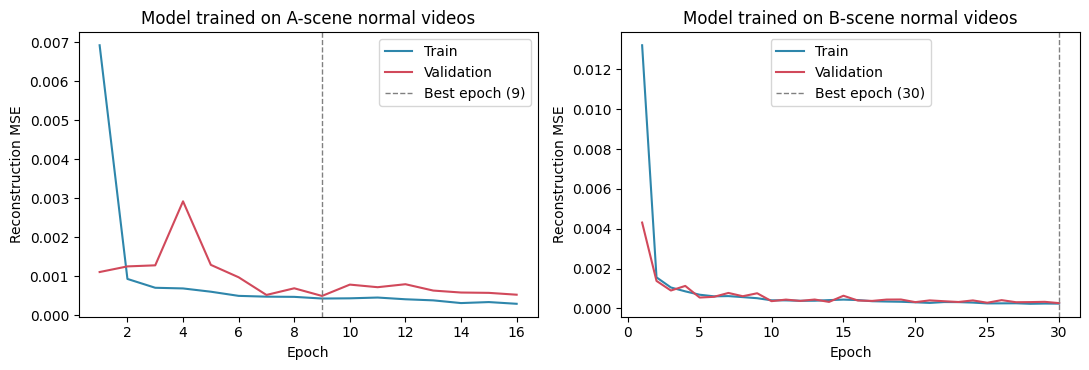

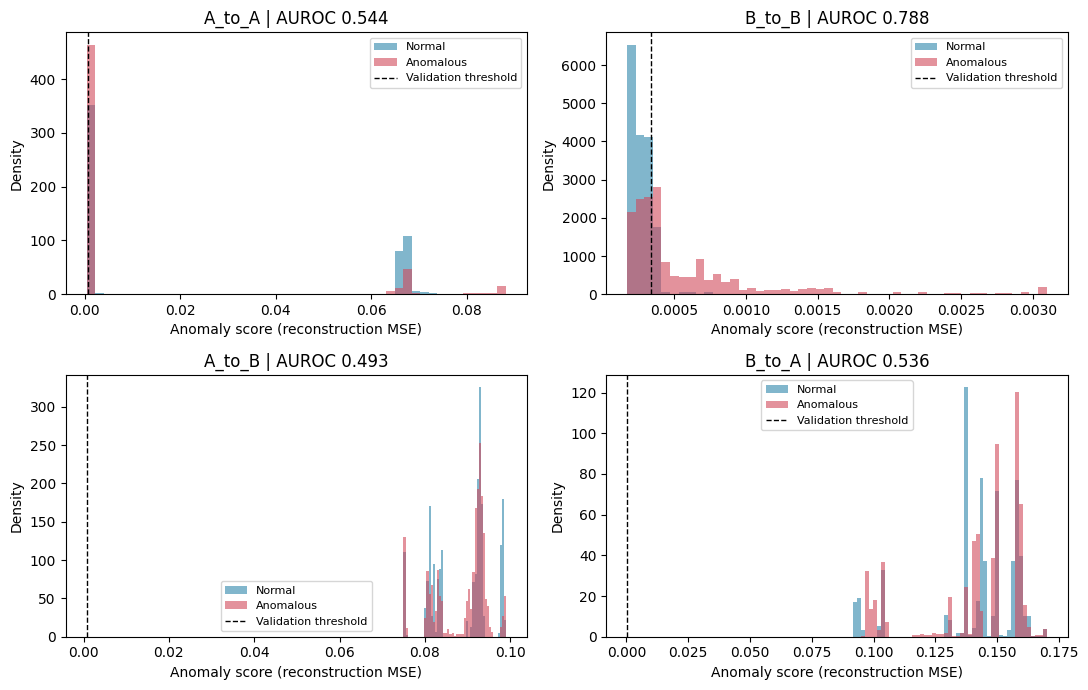

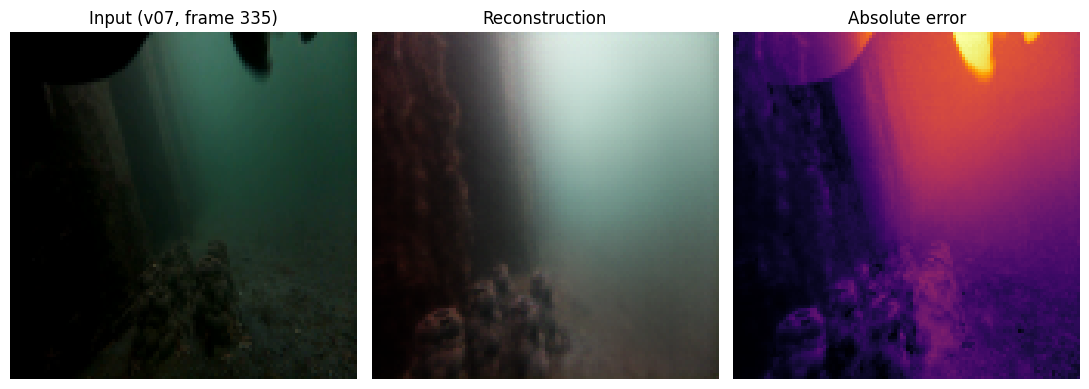

In [ ]:
#cell 12
# Visualize training curves and score separation

NORMAL_COLOR = "#2E86AB"
ANOMALY_COLOR = "#D1495B"

# Training curves
fig, axes = plt.subplots(1, len(history_by_model), figsize=(11, 3.8), squeeze=False)

for ax, (name, history) in zip(axes[0], history_by_model.items()):
    best_epoch = info_by_model[name]["best_epoch"]
    ax.plot(history["epoch"], history["train_loss"], color=NORMAL_COLOR, label="Train")
    ax.plot(history["epoch"], history["val_loss"], color=ANOMALY_COLOR, label="Validation")
    ax.axvline(best_epoch, color="gray", linestyle="--", linewidth=1,
               label=f"Best epoch ({best_epoch})")
    ax.set_title(f"Model trained on {name[0]}-scene normal videos")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Reconstruction MSE")
    ax.legend()

plt.tight_layout()
plt.savefig(BASELINE_DIR / "training_curves.png", dpi=150)
plt.show()

# Score distributions: normal vs anomalous windows
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

for ax, experiment in zip(axes.ravel(), experiments.keys()):
    scored = scores_by_experiment[experiment]
    row = baseline_results[baseline_results["experiment"] == experiment].iloc[0]

    upper = scored["score"].quantile(0.995)
    bins = np.linspace(scored["score"].min(), upper, 50)

    ax.hist(scored.loc[scored["binary_label"] == 0, "score"].clip(upper=upper),
            bins=bins, alpha=0.6, density=True, color=NORMAL_COLOR, label="Normal")
    ax.hist(scored.loc[scored["binary_label"] == 1, "score"].clip(upper=upper),
            bins=bins, alpha=0.6, density=True, color=ANOMALY_COLOR, label="Anomalous")
    ax.axvline(row["threshold"], color="black", linestyle="--", linewidth=1,
               label="Validation threshold")
    ax.set_title(f"{experiment} | AUROC {row['auroc']:.3f}")
    ax.set_xlabel("Anomaly score (reconstruction MSE)")
    ax.set_ylabel("Density")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(BASELINE_DIR / "score_distributions.png", dpi=150)
plt.show()

# Example reconstruction (Scene A, last frame of one anomalous window)
example_experiment = "A_to_A"
example = scores_by_experiment[example_experiment]
example_row = example[example["binary_label"] == 1].sort_values("score").iloc[-1]

example_model = build_model()
example_model.load_state_dict(
    load_checkpoint(CHECKPOINT_DIR / f"cnn_lstm_{example_experiment}.pt")["model_state"]
)
example_model.eval()

example_dataset = SequenceDataset(
    pd.DataFrame([example_row[["scene", "video", "frame_idx"]]])
)

with torch.no_grad():
    window = example_dataset[0].unsqueeze(0).to(DEVICE)
    reconstruction = example_model(window)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
original_frame = window[0, -1].permute(1, 2, 0).cpu().numpy()
rebuilt_frame = reconstruction[0, -1].permute(1, 2, 0).cpu().numpy()
error_map = np.abs(original_frame - rebuilt_frame).mean(axis=2)

axes[0].imshow(original_frame)
axes[0].set_title(f"Input ({example_row['video']}, frame {int(example_row['frame_idx'])})")
axes[1].imshow(np.clip(rebuilt_frame, 0, 1))
axes[1].set_title("Reconstruction")
axes[2].imshow(error_map, cmap="inferno")
axes[2].set_title("Absolute error")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.savefig(BASELINE_DIR / "example_reconstruction.png", dpi=150)
plt.show()
del example_model

In [ ]:
#cell 13
# Reproducibility check and handoff files for Member 4

# Reload each saved checkpoint, rescore its test sets and compare with the saved scores
reproducibility_rows = []

for train_experiment, experiments_to_run in TRAIN_PLAN.items():
    model = build_model()
    model.load_state_dict(
        load_checkpoint(CHECKPOINT_DIR / f"cnn_lstm_{train_experiment}.pt")["model_state"]
    )

    for experiment in experiments_to_run:
        saved = pd.read_csv(BASELINE_DIR / f"scores_{experiment}.csv")

        _, loader = make_loader(
            get_split(experiment, "test"), augment=False, shuffle=False,
            step=None, batch_size=EVAL_CONFIG["batch_size"]
        )
        rescored = score_windows(model, loader)

        max_difference = float(np.abs(rescored - saved["score"].to_numpy()).max())

        reproducibility_rows.append({
            "experiment": experiment,
            "windows": len(saved),
            "max_abs_score_difference": max_difference,
            "passed": bool(np.allclose(
                rescored, saved["score"].to_numpy(), rtol=1e-3, atol=1e-6
            ))
        })

    del model

reproducibility = pd.DataFrame(reproducibility_rows)
reproducibility.to_csv(BASELINE_DIR / "reproducibility_check.csv", index=False)

print("Reproducibility check (checkpoint reloaded and rescored):")
display(reproducibility)

if reproducibility["passed"].all():
    print("SUCCESS: saved checkpoints reproduce the recorded scores.")
else:
    print("WARNING: some scores differ. Review reproducibility_check.csv.")

# Save the full baseline configuration and results
baseline_record = {
    "model": MODEL_CONFIG,
    "training": TRAIN_CONFIG,
    "evaluation": EVAL_CONFIG,
    "trainable_parameters": int(total_parameters),
    "training_summary": info_by_model,
    "validation_thresholds": threshold_by_model,
    "results": baseline_results.to_dict("records"),
    "environment": {
        "pytorch": torch.__version__,
        "device": str(DEVICE),
        "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None
    }
}

with open(BASELINE_DIR / "baseline_config.json", "w", encoding="utf-8") as file:
    json.dump(baseline_record, file, indent=4, default=float)

handoff_text = f"""
CAI 421 - Member 2 CNN-LSTM Baseline

Model:
CNN-LSTM autoencoder trained only on normal AURA frames. A per-frame CNN
encoder feeds an LSTM that summarizes a 16-frame window; an LSTM decoder and
a CNN decoder reconstruct the window. {total_parameters:,} trainable parameters.

Anomaly score:
Mean squared reconstruction error of a 16-frame window, assigned to the last
frame of the window. Higher means more anomalous.

Windows:
16 frames. Frame stride is 2 in Scene A (30 fps) and 1 in Scene B (15 fps),
so each window covers about 1.07 seconds. Frames are resized to
{INPUT_SIZE}x{INPUT_SIZE}, RGB, scaled to [0, 1].

Training:
Adam (lr {TRAIN_CONFIG['learning_rate']}), MSE loss, batch size
{TRAIN_CONFIG['batch_size']}, up to {TRAIN_CONFIG['max_epochs']} epochs, early stopping
on validation loss (patience {TRAIN_CONFIG['early_stopping_patience']}), seed {SEED}.
One Scene A model serves A_to_A and A_to_B. One Scene B model serves B_to_B
and B_to_A. Best-validation checkpoints are kept.

Labels used for evaluation:
A_to_A and B_to_B use the hard labels in test_frames.csv (anomalous = 1).
A_to_B and B_to_A use soft_labels.csv; scores are compared against the soft
label directly (Spearman) and against soft_label >= {EVAL_CONFIG['soft_label_threshold']} for binary metrics.
The F1/precision/recall threshold is the {EVAL_CONFIG['validation_threshold_percentile']}th percentile of
validation (normal) scores.

Files in reports/cnn_lstm_baseline:
- baseline_results.csv          metrics for the four experiments
- scores_<experiment>.csv       per-window scores with labels (input for Member 4)
- training_history_<scene>.csv  loss per epoch
- architecture.csv              layers, output shapes, parameters
- baseline_config.json          all settings and results
- reproducibility_check.csv     checkpoint reload test
- checkpoints/                  trained weights
- training_curves.png, score_distributions.png, example_reconstruction.png

Cached decoded frames: cache/frames_{INPUT_SIZE}/ (can be deleted; they are rebuilt).
"""

(BASELINE_DIR / "README_member2.txt").write_text(handoff_text.strip(), encoding="utf-8")

print("\nBaseline config and handoff guide saved to:", BASELINE_DIR)

Reproducibility check (checkpoint reloaded and rescored):


,experiment,windows,max_abs_score_difference,passed
0,A_to_A,4277,3.722496e-09,True
1,A_to_B,2203,3.721428e-09,True
2,B_to_B,954,8.600867e-11,True
3,B_to_A,9506,7.450104e-09,True


SUCCESS: saved checkpoints reproduce the recorded scores.

Baseline config and handoff guide saved to: /content/drive/MyDrive/CAI421_Project/reports/cnn_lstm_baseline


Per-video diagnostics (does the signal exist inside each video?)


,experiment,video,windows,anomalous_percent,median_score,within_video_auroc_baseline_score,within_video_auroc_smoothed
0,A_to_A,v00,1309,15.8900,0.0004,0.8916,0.9120
1,A_to_A,v04,1586,33.2282,0.0007,0.6875,0.6886
2,A_to_A,v07,1382,10.7091,0.0669,0.7722,0.7855
3,B_to_B,v11,263,69.9620,0.0004,0.7854,0.7797
4,B_to_B,v16,202,67.8218,0.0002,0.9541,0.9745
5,B_to_B,v17,182,73.6264,0.0004,0.8966,0.8994
6,B_to_B,v19,181,56.3536,0.0003,0.9517,0.9741
7,B_to_B,v22,126,56.3492,0.0002,0.7859,0.7915
8,A_to_B,v10,148,62.8378,0.0935,0.8809,0.8958
9,A_to_B,v11,233,71.2446,0.0914,0.4398,0.4377



Mean within-video AUROC (videos with both normal and anomalous frames):


,within_video_auroc_baseline_score,within_video_auroc_smoothed
experiment,,
A_to_A,0.784,0.795
A_to_B,0.588,0.599
B_to_A,0.498,0.500
B_to_B,0.875,0.884



AUROC / AP by score variant (pooled over the whole test set)


variant,Baseline (raw MSE),Smoothed,Per-video normalized,Normalized + smoothed
experiment,,,,
A_to_A,0.544,0.546,0.746,0.753
B_to_B,0.788,0.788,0.854,0.859
A_to_B,0.493,0.495,0.557,0.566
B_to_A,0.536,0.536,0.492,0.491


variant,Baseline (raw MSE),Smoothed,Per-video normalized,Normalized + smoothed
experiment,,,,
A_to_A,0.264,0.269,0.439,0.447
B_to_B,0.893,0.893,0.926,0.926
A_to_B,0.572,0.575,0.703,0.716
B_to_A,0.294,0.296,0.283,0.283


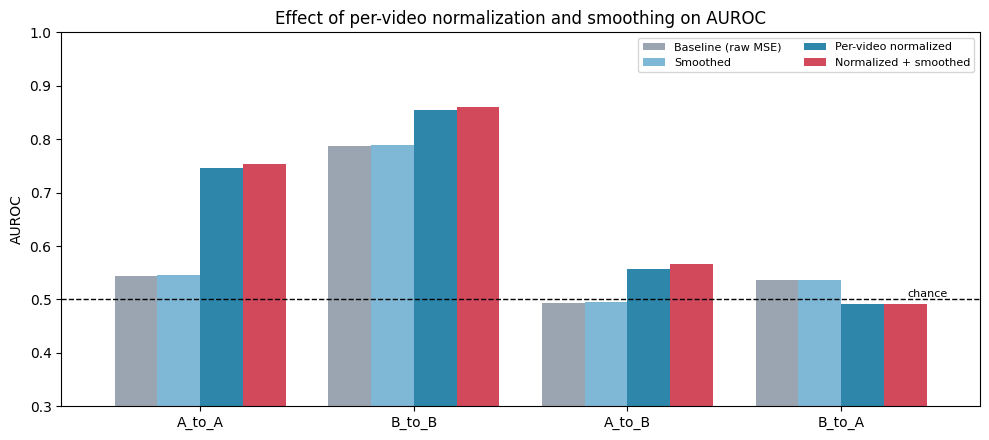

In [ ]:
#cell 14
# Post-hoc score improvement (no retraining): per-video normalization and temporal smoothing
#
# Why: the reconstruction error mostly measures how different a whole VIDEO looks from the
# training videos (lighting, colour), so every frame of an unusual video gets a high score.
# Normalizing the scores inside each video removes that offset, and smoothing over about one
# second uses the fact that real events last many frames.
#
# Note: the normalization uses the score statistics of each test video (never its labels).
# Report it as a test-time adjustment added on top of the original baseline.

SMOOTH_SECONDS = 1.0
SCENE_FPS = {"Scene_A": 30, "Scene_B": 15}
EPS = 1e-12

VARIANTS = {
    "baseline_score": "Baseline (raw MSE)",
    "smoothed": "Smoothed",
    "video_norm": "Per-video normalized",
    "video_norm_smoothed": "Normalized + smoothed"
}


def per_video_groups(df):
    return df.groupby(["scene", "video"], sort=True)


def smooth_scores(df, column):
    # Centered moving average over about SMOOTH_SECONDS, measured in frame indices
    out = pd.Series(np.nan, index=df.index, dtype=float)

    for (scene, _), group in per_video_groups(df):
        group = group.sort_values("frame_idx")
        window = max(1, round(SCENE_FPS[scene] * SMOOTH_SECONDS))

        series = pd.Series(
            group[column].to_numpy(),
            index=pd.to_timedelta(group["frame_idx"].to_numpy(), unit="ms")
        )
        smoothed = series.rolling(f"{window}ms", center=True, min_periods=1).mean()
        out.loc[group.index] = smoothed.to_numpy()

    return out


def normalize_per_video(df, column):
    # Robust z-score inside each video: (value - median) / (1.4826 * MAD)
    out = pd.Series(np.nan, index=df.index, dtype=float)

    for _, group in per_video_groups(df):
        values = group[column].to_numpy()
        median = np.median(values)
        mad = 1.4826 * np.median(np.abs(values - median))
        out.loc[group.index] = (values - median) / (mad + EPS)

    return out


def rank_metrics(values, binary, soft_target, has_soft):
    both_classes = len(np.unique(binary)) == 2
    return {
        "auroc": roc_auc_score(binary, values) if both_classes else np.nan,
        "average_precision": (
            average_precision_score(binary, values) if both_classes else np.nan
        ),
        "spearman_vs_soft_label": (
            spearmanr(values, soft_target).correlation if has_soft else np.nan
        )
    }


comparison_rows = []
video_rows = []

for experiment, (_, _, mode) in experiments.items():
    scored = pd.read_csv(BASELINE_DIR / f"scores_{experiment}.csv")
    scored["video"] = scored["video"].astype(str)
    scored["baseline_score"] = scored["score"]

    log_score = np.log(scored["score"] + EPS)
    scored["log_score"] = log_score
    scored["smoothed"] = smooth_scores(scored, "log_score")
    scored["video_norm"] = normalize_per_video(scored, "log_score")
    scored["video_norm_smoothed"] = smooth_scores(scored, "video_norm")

    binary = scored["binary_label"].to_numpy()
    soft_target = scored["soft_target"].to_numpy()
    has_soft = mode == "cross_scene"

    for key, name in VARIANTS.items():
        comparison_rows.append({
            "experiment": experiment,
            "variant": name,
            **rank_metrics(scored[key].to_numpy(), binary, soft_target, has_soft)
        })

    # Does the signal exist INSIDE each video? (AUROC computed one video at a time)
    for (scene, video), group in per_video_groups(scored):
        labels = group["binary_label"].to_numpy()
        row = {
            "experiment": experiment,
            "video": video,
            "windows": len(group),
            "anomalous_percent": 100 * labels.mean(),
            "median_score": group["baseline_score"].median()
        }

        for key in ["baseline_score", "smoothed"]:
            row[f"within_video_auroc_{key}"] = (
                roc_auc_score(labels, group[key])
                if len(np.unique(labels)) == 2 else np.nan
            )

        video_rows.append(row)

    scored.drop(columns=["log_score"]).to_csv(
        BASELINE_DIR / f"scores_improved_{experiment}.csv", index=False
    )

comparison = pd.DataFrame(comparison_rows)
per_video = pd.DataFrame(video_rows)

comparison.to_csv(BASELINE_DIR / "score_postprocessing_results.csv", index=False)
per_video.to_csv(BASELINE_DIR / "per_video_diagnostics.csv", index=False)

print("Per-video diagnostics (does the signal exist inside each video?)")
display(per_video.round(4))

summary = per_video.groupby("experiment")[
    ["within_video_auroc_baseline_score", "within_video_auroc_smoothed"]
].mean()
print("\nMean within-video AUROC (videos with both normal and anomalous frames):")
display(summary.round(3))

print("\nAUROC / AP by score variant (pooled over the whole test set)")
display(
    comparison.pivot(index="experiment", columns="variant", values="auroc")[
        list(VARIANTS.values())
    ].loc[list(experiments.keys())].round(3)
)
display(
    comparison.pivot(index="experiment", columns="variant", values="average_precision")[
        list(VARIANTS.values())
    ].loc[list(experiments.keys())].round(3)
)

# Chart
palette = ["#9AA5B1", "#7FB7D6", "#2E86AB", "#D1495B"]
pivot = comparison.pivot(index="experiment", columns="variant", values="auroc")[
    list(VARIANTS.values())
].loc[list(experiments.keys())]

ax = pivot.plot(kind="bar", figsize=(10, 4.5), color=palette, width=0.8, rot=0)
ax.axhline(0.5, color="black", linestyle="--", linewidth=1)
ax.text(len(pivot) - 0.5, 0.505, "chance", ha="right", fontsize=8)
ax.set_ylabel("AUROC")
ax.set_xlabel("")
ax.set_ylim(0.3, 1.0)
ax.set_title("Effect of per-video normalization and smoothing on AUROC")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.savefig(BASELINE_DIR / "score_postprocessing_auroc.png", dpi=150)
plt.show()


v2 checks passed.
Batch: (16, 16, 3, 112, 112) | normalized std per channel (mean): 0.958397626876831
Trainable parameters: 5,005,987


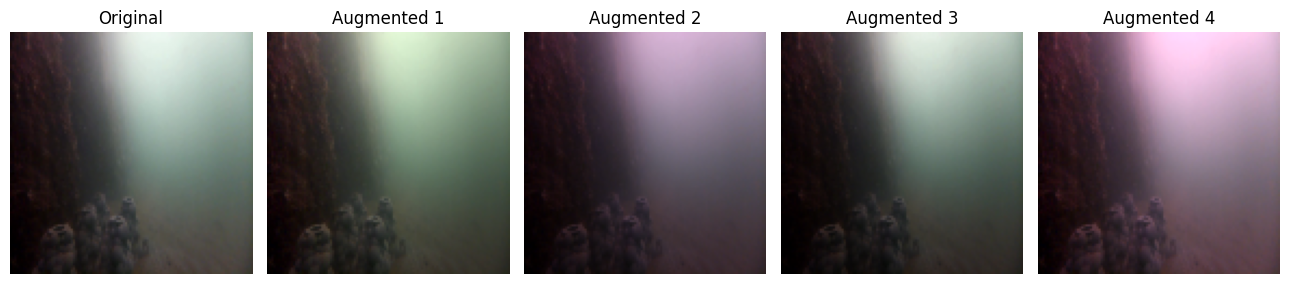

In [ ]:
#cell 15
# v2 model: stronger lighting/colour augmentation, per-window normalization, patch-based scores
#
# What changes compared with the baseline (cells 6 to 13):
#   1. Training windows get random gamma, illumination gradient, colour gain and brightness,
#      so the model sees many lighting conditions instead of only the training videos.
#   2. Every window is normalized per colour channel (mean 0, std 1 over the 16 frames) before
#      it enters the network, which removes global brightness and colour differences.
#      The network therefore reconstructs the normalized window (no Sigmoid at the output).
#   3. The anomaly score can be taken from the worst image patches instead of the whole image,
#      so a small animal is not averaged away by the background.
# Cell 14 must have been run first (its helper functions are reused in cell 17).

PATCH_GRID = 8
PATCH_SIZE = INPUT_SIZE // PATCH_GRID
if INPUT_SIZE % PATCH_GRID != 0:
    raise ValueError("input_size must be divisible by 8 for the patch scores.")

V2_CONFIG = {
    "augmentation": {
        "gamma": [0.7, 1.4],
        "illumination_gradient": 0.4,
        "color_gain": [0.8, 1.2],
        "brightness": [0.7, 1.3]
    },
    "window_normalization": "per colour channel, mean 0 and std 1 over the 16-frame window",
    "normalization_eps": 0.01,
    "output_activation": "none (reconstructs the normalized window)",
    "patch_size": PATCH_SIZE,
    "score_types": ["score_mean", "score_patch_max", "score_patch_top5"],
    "max_epochs": 40,
    "early_stopping_patience": 8
}


def augment_batch(x):
    # x: (batch, time, 3, height, width) in [0, 1]; one random setting per window
    batch, _, _, height, width = x.shape
    device = x.device
    settings = V2_CONFIG["augmentation"]

    def uniform(low, high, shape):
        return torch.empty(shape, device=device).uniform_(low, high)

    gamma = uniform(*settings["gamma"], (batch, 1, 1, 1, 1))
    x = x.clamp_min(1e-4) ** gamma

    # Smooth left-right / top-bottom illumination change (light shafts, shadows)
    slope = settings["illumination_gradient"]
    slope_x = uniform(-slope, slope, (batch, 1, 1, 1, 1))
    slope_y = uniform(-slope, slope, (batch, 1, 1, 1, 1))
    xs = torch.linspace(-1, 1, width, device=device).view(1, 1, 1, 1, width)
    ys = torch.linspace(-1, 1, height, device=device).view(1, 1, 1, height, 1)
    x = x * (1 + slope_x * xs + slope_y * ys)

    color = uniform(*settings["color_gain"], (batch, 1, 3, 1, 1))
    brightness = uniform(*settings["brightness"], (batch, 1, 1, 1, 1))

    return (x * color * brightness).clamp(0, 1)


def normalize_window(x):
    mean = x.mean(dim=(1, 3, 4), keepdim=True)
    std = x.std(dim=(1, 3, 4), keepdim=True)
    return (x - mean) / (std + V2_CONFIG["normalization_eps"])


def build_model_v2():
    model = build_model()
    model.decoder.deconv[-1] = nn.Identity()
    return model


# Checks on one real batch
_, _probe_loader_v2 = make_loader(
    frame_splits[
        (frame_splits["experiment"] == "A_to_A") & (frame_splits["split"] == "train")
    ],
    augment=False, shuffle=False, step=TRAIN_CONFIG["window_step"],
    batch_size=TRAIN_CONFIG["batch_size"]
)
probe = next(iter(_probe_loader_v2)).to(DEVICE)

augmented = augment_batch(probe)
normalized = normalize_window(augmented)

if augmented.shape != probe.shape or normalized.shape != probe.shape:
    raise ValueError("Augmentation or normalization changed the batch shape.")
if not torch.isfinite(normalized).all():
    raise ValueError("Normalized batch contains NaN or infinite values.")
if augmented.min() < 0 or augmented.max() > 1:
    raise ValueError("Augmented pixels must stay within [0, 1].")
if normalized.mean(dim=(1, 3, 4)).abs().max() > 1e-3:
    raise ValueError("Window normalization did not center the channels.")

_model_v2 = build_model_v2()
_model_v2.eval()
with torch.no_grad():
    _reconstruction = _model_v2(normalized[:2])

if _reconstruction.shape != normalized[:2].shape:
    raise ValueError("v2 reconstruction shape does not match the input shape.")

print("v2 checks passed.")
print("Batch:", tuple(probe.shape), "| normalized std per channel (mean):",
      float(normalized.std(dim=(1, 3, 4)).mean()))
print("Trainable parameters:", f"{sum(p.numel() for p in _model_v2.parameters()):,}")
del _model_v2

# Preview: the original last frame and four random augmentations of it
preview_source = probe[:1].repeat(4, 1, 1, 1, 1)
preview = augment_batch(preview_source)

fig, axes = plt.subplots(1, 5, figsize=(13, 3))
axes[0].imshow(probe[0, -1].permute(1, 2, 0).cpu().numpy())
axes[0].set_title("Original")

for i in range(4):
    axes[i + 1].imshow(preview[i, -1].permute(1, 2, 0).cpu().numpy())
    axes[i + 1].set_title(f"Augmented {i + 1}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
(BASELINE_DIR / "v2").mkdir(parents=True, exist_ok=True)
plt.savefig(BASELINE_DIR / "v2" / "augmentation_preview.png", dpi=150)
plt.show()

In [ ]:
#cell 16
# v2: train on normal videos only (same splits as the baseline), then score the four experiments

V2_DIR = BASELINE_DIR / "v2"
V2_CHECKPOINT_DIR = V2_DIR / "checkpoints"
V2_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)


@torch.no_grad()
def score_windows_v2(model, loader):
    # Three scores per window, all computed on the normalized window in full precision:
    #   score_mean       mean squared error over the whole image (same idea as the baseline)
    #   score_patch_max  error of the worst patch of the 8x8 patch grid
    #   score_patch_top5 mean error of the 5 worst patches
    model.eval()
    collected = {name: [] for name in V2_CONFIG["score_types"]}

    for batch in loader:
        batch = batch.to(DEVICE, non_blocking=True)
        target = normalize_window(batch)
        reconstruction = model(target)

        error = ((reconstruction - target) ** 2).mean(dim=2)   # (batch, time, H, W)
        error = error.mean(dim=1)                              # (batch, H, W)
        patches = F.avg_pool2d(error.unsqueeze(1), PATCH_SIZE).flatten(1)

        collected["score_mean"].append(error.mean(dim=(1, 2)).cpu().numpy())
        collected["score_patch_max"].append(patches.max(dim=1).values.cpu().numpy())
        top = min(5, patches.size(1))
        collected["score_patch_top5"].append(
            patches.topk(top, dim=1).values.mean(dim=1).cpu().numpy()
        )

    return {name: np.concatenate(values) for name, values in collected.items()}


def train_model_v2(train_df, val_df):
    seed_everything()
    model = build_model_v2()

    _, train_loader = make_loader(
        train_df, augment=False, shuffle=True,
        step=TRAIN_CONFIG["window_step"], batch_size=TRAIN_CONFIG["batch_size"]
    )
    _, val_loader = make_loader(
        val_df, augment=False, shuffle=False,
        step=TRAIN_CONFIG["window_step"], batch_size=EVAL_CONFIG["batch_size"]
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=TRAIN_CONFIG["learning_rate"],
        weight_decay=TRAIN_CONFIG["weight_decay"]
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=3
    )
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    best_val, best_epoch, best_state = float("inf"), 0, None
    epochs_without_improvement = 0
    history = []
    start = time.time()

    for epoch in range(1, V2_CONFIG["max_epochs"] + 1):
        model.train()
        running_loss, seen = 0.0, 0

        for batch in train_loader:
            batch = batch.to(DEVICE, non_blocking=True)
            target = normalize_window(augment_batch(batch))
            optimizer.zero_grad(set_to_none=True)

            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16,
                                enabled=USE_AMP):
                reconstruction = model(target)

            loss = F.mse_loss(reconstruction.float(), target)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), TRAIN_CONFIG["grad_clip_norm"])
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item() * batch.size(0)
            seen += batch.size(0)

        train_loss = running_loss / seen
        val_loss = float(score_windows_v2(model, val_loader)["score_mean"].mean())
        scheduler.step(val_loss)

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "lr": optimizer.param_groups[0]["lr"]
        })

        improved = val_loss < best_val
        if improved:
            best_val, best_epoch = val_loss, epoch
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        print(f"  epoch {epoch:02d} | train {train_loss:.4f} | "
              f"val {val_loss:.4f}{' *' if improved else ''}")

        if epochs_without_improvement >= V2_CONFIG["early_stopping_patience"]:
            print(f"  early stopping at epoch {epoch}")
            break

    model.load_state_dict(best_state)

    info = {
        "best_epoch": best_epoch,
        "best_val_loss": best_val,
        "epochs_run": len(history),
        "train_seconds": time.time() - start,
        "v2_config": V2_CONFIG
    }

    return model, pd.DataFrame(history), info


v2_history = {}
v2_info = {}

for train_experiment, experiments_to_run in TRAIN_PLAN.items():

    train_df = get_split(train_experiment, "train")
    val_df = get_split(train_experiment, "validation")

    checkpoint_path = V2_CHECKPOINT_DIR / f"cnn_lstm_v2_{train_experiment}.pt"
    reuse = False

    if checkpoint_path.exists() and not FORCE_RETRAIN:
        checkpoint = load_checkpoint(checkpoint_path)
        reuse = (
            checkpoint["model_config"] == MODEL_CONFIG
            and checkpoint["train_config"] == TRAIN_CONFIG
            and checkpoint["info"].get("v2_config") == V2_CONFIG
        )

    print(f"\n=== v2 model trained on {train_experiment} "
          f"(serves {', '.join(experiments_to_run)}) ===")

    if reuse:
        print("  Loading saved v2 checkpoint (settings match).")
        model = build_model_v2()
        model.load_state_dict(checkpoint["model_state"])
        history = pd.DataFrame(checkpoint["history"])
        info = checkpoint["info"]
    else:
        model, history, info = train_model_v2(train_df, val_df)
        save_checkpoint(checkpoint_path, model, info, history)

    history.to_csv(V2_DIR / f"training_history_v2_{train_experiment}.csv", index=False)
    v2_history[train_experiment] = history
    v2_info[train_experiment] = info

    for experiment in experiments_to_run:
        test_dataset, test_loader = make_loader(
            get_split(experiment, "test"), augment=False, shuffle=False,
            step=None, batch_size=EVAL_CONFIG["batch_size"]
        )
        score_values = score_windows_v2(model, test_loader)

        scored = test_dataset.df.copy()
        for name, values in score_values.items():
            scored[name] = values

        binary, soft_target, _ = build_targets(scored)
        scored["binary_label"] = binary
        scored["soft_target"] = soft_target
        scored.to_csv(V2_DIR / f"scores_v2_{experiment}.csv", index=False)

        quick = {
            name: roc_auc_score(binary, scored[name])
            for name in V2_CONFIG["score_types"]
        }
        print(f"  {experiment} raw AUROC | "
              + " | ".join(f"{k.replace('score_', '')} {v:.3f}" for k, v in quick.items()))

print("\nv2 training and scoring finished. Next cell compares v2 with the baseline.")


=== v2 model trained on A_to_A (serves A_to_A, A_to_B) ===
  epoch 01 | train 0.1164 | val 0.0165 *
  epoch 02 | train 0.0268 | val 0.0159 *
  epoch 03 | train 0.0208 | val 0.0136 *
  epoch 04 | train 0.0178 | val 0.0121 *


In [ ]:
#cell 17
# v2 vs baseline: per-video normalization + smoothing applied to the v2 scores, comparison table and chart
#
# Planned main result (decided before looking at the numbers): "v2 top-5 patches | normalized + smoothed".
# The other variants are an ablation. Do not pick the best column per experiment on the test labels
# and present it as the result; report the planned variant and show the rest as analysis.

V2_SCORE_LABELS = {
    "score_mean": "v2 mean",
    "score_patch_max": "v2 patch-max",
    "score_patch_top5": "v2 top-5 patches"
}
PRIMARY_V2_VARIANT = "v2 top-5 patches | normalized + smoothed"

v2_rows = []
final_scores = {}

for experiment, (_, _, mode) in experiments.items():
    scored = pd.read_csv(V2_DIR / f"scores_v2_{experiment}.csv")
    scored["video"] = scored["video"].astype(str)

    binary = scored["binary_label"].to_numpy()
    soft_target = scored["soft_target"].to_numpy()
    has_soft = mode == "cross_scene"

    for score_name, label in V2_SCORE_LABELS.items():
        scored["_log"] = np.log(scored[score_name] + EPS)
        scored["_norm"] = normalize_per_video(scored, "_log")
        scored["_norm_smoothed"] = smooth_scores(scored, "_norm")

        for suffix, column in [("raw", score_name), ("normalized + smoothed", "_norm_smoothed")]:
            v2_rows.append({
                "experiment": experiment,
                "variant": f"{label} | {suffix}",
                **rank_metrics(scored[column].to_numpy(), binary, soft_target, has_soft)
            })

        scored[f"{score_name}_norm_smoothed"] = scored["_norm_smoothed"]

    scored["v2_final_score"] = scored["score_patch_top5_norm_smoothed"]
    scored.drop(columns=["_log", "_norm", "_norm_smoothed"]).to_csv(
        V2_DIR / f"scores_v2_final_{experiment}.csv", index=False
    )

v2_comparison = pd.DataFrame(v2_rows)

# Baseline (v1) numbers from cell 14
v1 = comparison[
    comparison["variant"].isin(["Baseline (raw MSE)", "Normalized + smoothed"])
].copy()
v1["variant"] = v1["variant"].map({
    "Baseline (raw MSE)": "v1 baseline | raw",
    "Normalized + smoothed": "v1 baseline | normalized + smoothed"
})

full_comparison = pd.concat([v1, v2_comparison], ignore_index=True)
full_comparison.to_csv(V2_DIR / "v1_vs_v2_comparison.csv", index=False)

column_order = ["v1 baseline | raw", "v1 baseline | normalized + smoothed"] + [
    f"{label} | {suffix}"
    for label in V2_SCORE_LABELS.values()
    for suffix in ["raw", "normalized + smoothed"]
]
row_order = list(experiments.keys())

auroc_table = full_comparison.pivot(
    index="experiment", columns="variant", values="auroc"
)[column_order].loc[row_order]
ap_table = full_comparison.pivot(
    index="experiment", columns="variant", values="average_precision"
)[column_order].loc[row_order]

print("AUROC (pooled over each test set)")
display(auroc_table.round(3))
print("\nAverage precision")
display(ap_table.round(3))

print(f"\nPlanned main v2 result: {PRIMARY_V2_VARIANT}")
summary = pd.DataFrame({
    "v1 baseline (raw)": auroc_table["v1 baseline | raw"],
    "v1 normalized + smoothed": auroc_table["v1 baseline | normalized + smoothed"],
    "v2 main": auroc_table[PRIMARY_V2_VARIANT]
})
summary["v2 main minus v1 raw"] = summary["v2 main"] - summary["v1 baseline (raw)"]
display(summary.round(3))

# Chart
palette = ["#9AA5B1", "#5F6B7A", "#7FB7D6", "#2E86AB",
           "#F2B880", "#E07A2F", "#E5A0AB", "#D1495B"]

ax = auroc_table.plot(kind="bar", figsize=(13, 5), color=palette, width=0.85, rot=0)
ax.axhline(0.5, color="black", linestyle="--", linewidth=1)
ax.set_ylabel("AUROC")
ax.set_xlabel("")
ax.set_ylim(0.3, 1.0)
ax.set_title("Baseline (v1) vs v2: AUROC by score variant")
ax.legend(fontsize=7, ncol=2, loc="upper right")
plt.tight_layout()
plt.savefig(V2_DIR / "v1_vs_v2_auroc.png", dpi=150)
plt.show()

# Training curves of the v2 models
fig, axes = plt.subplots(1, len(v2_history), figsize=(11, 3.8), squeeze=False)

for ax, (name, history) in zip(axes[0], v2_history.items()):
    best_epoch = v2_info[name]["best_epoch"]
    ax.plot(history["epoch"], history["train_loss"], color="#2E86AB", label="Train")
    ax.plot(history["epoch"], history["val_loss"], color="#D1495B", label="Validation")
    ax.axvline(best_epoch, color="gray", linestyle="--", linewidth=1,
               label=f"Best epoch ({best_epoch})")
    ax.set_title(f"v2 trained on {name[0]}-scene normal videos")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE (normalized windows)")
    ax.legend()

plt.tight_layout()
plt.savefig(V2_DIR / "training_curves_v2.png", dpi=150)
plt.show()

with open(V2_DIR / "v2_config.json", "w", encoding="utf-8") as file:
    json.dump({
        "v2": V2_CONFIG,
        "training_summary": v2_info,
        "primary_variant": PRIMARY_V2_VARIANT,
        "auroc": auroc_table.round(4).reset_index().to_dict("records")
    }, file, indent=4, default=float)

print("v2 results saved to:", V2_DIR)

## Experiment: mixed-scene training (separate from the approved baseline)
One model trained on normal videos from both scenes. Cross-scene tests exclude videos seen in training.

In [ ]:
# cell 18 (EXPERIMENT): mixed-scene training
# Goal: one model trained on NORMAL training videos from BOTH scenes, evaluated on all four settings.
# Protocol change (declared in the report): a cross-scene test keeps only target-scene videos that
# were NOT used for training or validation by the mixed model. Without this filter, training on
# Scene B normal videos would leak into the A_to_B test set (and the same for B_to_A).
# Separate experiment: approved baseline files (cells 6 to 14) are read-only here and are not overwritten.

MIXED_DIR = REPORTS_DIR / "cnn_lstm_mixed_experiment"
MIXED_CHECKPOINT_DIR = MIXED_DIR / "checkpoints"
MIXED_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
APPROVED_CHECKPOINT_DIR = REPORTS_DIR / "cnn_lstm_baseline" / "checkpoints"

mixed_train_df = pd.concat(
    [get_split("A_to_A", "train"), get_split("B_to_B", "train")], ignore_index=True
)
mixed_val_df = pd.concat(
    [get_split("A_to_A", "validation"), get_split("B_to_B", "validation")], ignore_index=True
)

# Every video the mixed model has seen (training or validation)
used_videos = (
    set(zip(mixed_train_df["scene"], mixed_train_df["video"].astype(str)))
    | set(zip(mixed_val_df["scene"], mixed_val_df["video"].astype(str)))
)


def remove_used_videos(df, used):
    keep = [
        (scene, str(video)) not in used
        for scene, video in zip(df["scene"], df["video"])
    ]
    return df[np.array(keep, dtype=bool)].copy()


mixed_path = MIXED_CHECKPOINT_DIR / "cnn_lstm_mixed.pt"
if mixed_path.exists() and not FORCE_RETRAIN:
    checkpoint = load_checkpoint(mixed_path)
    mixed_model = build_model()
    mixed_model.load_state_dict(checkpoint["model_state"])
    mixed_model.eval()
    mixed_history = pd.DataFrame(checkpoint["history"])
    mixed_info = checkpoint["info"]
    print("Loaded saved mixed-scene checkpoint.")
else:
    print("Training mixed-scene model on normal videos from both scenes.")
    mixed_model, mixed_history, mixed_info = train_model(mixed_train_df, mixed_val_df)
    save_checkpoint(mixed_path, mixed_model, mixed_info, mixed_history)

mixed_history.to_csv(MIXED_DIR / "training_history_mixed.csv", index=False)

# Threshold: same rule as the baseline (99th percentile of validation normal scores)
_, mixed_val_loader = make_loader(
    mixed_val_df, augment=False, shuffle=False,
    step=TRAIN_CONFIG["window_step"], batch_size=EVAL_CONFIG["batch_size"]
)
mixed_threshold = float(np.percentile(
    score_windows(mixed_model, mixed_val_loader),
    EVAL_CONFIG["validation_threshold_percentile"]
))

BASELINE_SOURCE = {"A_to_A": "A_to_A", "A_to_B": "A_to_A", "B_to_B": "B_to_B", "B_to_A": "B_to_B"}

mixed_rows = []

for experiment in ["A_to_A", "B_to_B", "A_to_B", "B_to_A"]:
    _, _, mode = experiments[experiment]
    test_df = get_split(experiment, "test")

    if mode == "cross_scene":
        before = len(test_df)
        test_df = remove_used_videos(test_df, used_videos)
        excluded_windows = before - len(test_df)
    else:
        # Within-scene tests use original test videos; they must not overlap training
        test_pairs = set(zip(test_df["scene"], test_df["video"].astype(str)))
        if test_pairs & used_videos:
            raise ValueError(f"{experiment}: test videos overlap the mixed training data.")
        excluded_windows = 0

    if len(test_df) == 0:
        raise ValueError(f"{experiment}: no test windows remain after filtering.")

    test_dataset, test_loader = make_loader(
        test_df, augment=False, shuffle=False, step=None, batch_size=EVAL_CONFIG["batch_size"]
    )
    binary, soft_target, has_soft = build_targets(test_dataset.df.copy())

    mixed_scores = score_windows(mixed_model, test_loader)

    base_checkpoint = load_checkpoint(
        APPROVED_CHECKPOINT_DIR / f"cnn_lstm_{BASELINE_SOURCE[experiment]}.pt"
    )
    base_model = build_model()
    base_model.load_state_dict(base_checkpoint["model_state"])
    base_model.eval()
    base_scores = score_windows(base_model, test_loader)
    del base_model

    mixed_metrics = evaluate_scores(mixed_scores, binary, soft_target, has_soft, mixed_threshold)

    for model_name, scores in [
        ("approved baseline (same windows)", base_scores),
        ("mixed-scene model", mixed_scores),
    ]:
        row = {
            "experiment": experiment,
            "model": model_name,
            "test_windows": len(test_dataset.df),
            "windows_removed_for_leakage": excluded_windows,
            "anomalous_share": float(binary.mean()),
            **rank_metrics(scores, binary, soft_target, has_soft),
        }
        if model_name == "mixed-scene model":
            row.update({k: mixed_metrics[k] for k in ["threshold", "precision", "recall", "f1"]})
        mixed_rows.append(row)

mixed_results = pd.DataFrame(mixed_rows)
mixed_results.to_csv(MIXED_DIR / "mixed_scene_results.csv", index=False)

print("Mixed-scene experiment (AUROC and AP are threshold-free; compare each row with its baseline row):")
display(mixed_results.round(4))

with open(MIXED_DIR / "mixed_scene_config.json", "w", encoding="utf-8") as file:
    json.dump({
        "protocol_change": "cross-scene tests exclude videos used by the mixed model for training or validation",
        "training_scenes": ["Scene_A", "Scene_B"],
        "threshold_rule": "99th percentile of mixed validation normal scores",
        "training_summary": mixed_info,
        "results": mixed_results.round(4).to_dict("records")
    }, file, indent=4, default=float)

print("Mixed-scene results saved to:", MIXED_DIR)


In [ ]:

# cell 19 (EXPERIMENT, post-processing of the mixed model)
# Adds the two score changes that helped the approved model in cells 14 and 17:
#   (a) top-5 patch score on the 8x8 grid, instead of the whole-image mean
#   (b) per-video robust normalization and 1-second smoothing (TEST-TIME ADJUSTMENT)
# Reported side by side with the raw mixed score. The primary variant is chosen before looking at results.

PRIMARY_MIXED_VARIANT = "mixed | top-5 patches | normalized + smoothed"

PATCH_GRID_MIXED = 8
PATCH_SIZE_MIXED = INPUT_SIZE // PATCH_GRID_MIXED


@torch.no_grad()
def score_patch_top5(model, loader):
    # Mean squared error per patch (8x8 grid), averaged over time and channels; keep the 5 worst patches
    model.eval()
    collected = []
    for batch in loader:
        batch = batch.to(DEVICE, non_blocking=True)
        reconstruction = model(batch)
        error = ((reconstruction - batch) ** 2).mean(dim=2).mean(dim=1)   # (batch, H, W)
        patches = F.avg_pool2d(error.unsqueeze(1), PATCH_SIZE_MIXED).flatten(1)
        top = min(5, patches.size(1))
        collected.append(patches.topk(top, dim=1).values.mean(dim=1).cpu().numpy())
    return np.concatenate(collected)


post_rows = []

for experiment in ["A_to_A", "B_to_B", "A_to_B", "B_to_A"]:
    _, _, mode = experiments[experiment]
    test_df = get_split(experiment, "test")
    if mode == "cross_scene":
        test_df = remove_used_videos(test_df, used_videos)

    test_dataset, test_loader = make_loader(
        test_df, augment=False, shuffle=False, step=None, batch_size=EVAL_CONFIG["batch_size"]
    )
    binary, soft_target, has_soft = build_targets(test_dataset.df.copy())

    scored = test_dataset.df.copy()
    scored["video"] = scored["video"].astype(str)
    scored["_mean"] = score_windows(mixed_model, test_loader)
    scored["_top5"] = score_patch_top5(mixed_model, test_loader)

    scored["_log_top5"] = np.log(scored["_top5"] + EPS)
    scored["_norm_top5"] = normalize_per_video(scored, "_log_top5")
    scored["_norm_smoothed_top5"] = smooth_scores(scored, "_norm_top5")

    variants = {
        "mixed | mean raw": "_mean",
        "mixed | top-5 patches | raw": "_top5",
        PRIMARY_MIXED_VARIANT: "_norm_smoothed_top5",
    }
    for name, column in variants.items():
        post_rows.append({
            "experiment": experiment,
            "variant": name,
            "anomalous_share": float(binary.mean()),
            **rank_metrics(scored[column].to_numpy(), binary, soft_target, has_soft),
        })

post_results = pd.DataFrame(post_rows)
post_results.to_csv(MIXED_DIR / "mixed_scene_postprocessing.csv", index=False)

print("Mixed model: raw and post-processed scores (post-processing uses test-video score statistics; report it separately).")
display(post_results.round(4))
print("Primary variant:", PRIMARY_MIXED_VARIANT)
print("Saved to:", MIXED_DIR / "mixed_scene_postprocessing.csv")


In [ ]:
# cell 20 (CHECK): approved baseline with the SAME post-processing as the mixed model
# Gives a fair comparison: both models get top-5 patches + per-video normalization + smoothing.
# Uses the approved checkpoints read-only; nothing is retrained or overwritten.

fair_rows = []

for experiment in ["A_to_A", "B_to_B", "A_to_B", "B_to_A"]:
    _, _, mode = experiments[experiment]
    test_df = get_split(experiment, "test")
    if mode == "cross_scene":
        test_df = remove_used_videos(test_df, used_videos)

    test_dataset, test_loader = make_loader(
        test_df, augment=False, shuffle=False, step=None, batch_size=EVAL_CONFIG["batch_size"]
    )
    binary, soft_target, has_soft = build_targets(test_dataset.df.copy())

    base_checkpoint = load_checkpoint(
        APPROVED_CHECKPOINT_DIR / f"cnn_lstm_{BASELINE_SOURCE[experiment]}.pt"
    )
    base_model = build_model()
    base_model.load_state_dict(base_checkpoint["model_state"])
    base_model.eval()

    scored = test_dataset.df.copy()
    scored["video"] = scored["video"].astype(str)
    scored["_top5"] = score_patch_top5(base_model, test_loader)
    del base_model

    scored["_log_top5"] = np.log(scored["_top5"] + EPS)
    scored["_norm_top5"] = normalize_per_video(scored, "_log_top5")
    scored["_norm_smoothed_top5"] = smooth_scores(scored, "_norm_top5")

    fair_rows.append({
        "experiment": experiment,
        "variant": "approved | top-5 patches | normalized + smoothed (same as mixed)",
        "anomalous_share": float(binary.mean()),
        **rank_metrics(scored["_norm_smoothed_top5"].to_numpy(), binary, soft_target, has_soft),
    })

fair_results = pd.DataFrame(fair_rows)
fair_results.to_csv(MIXED_DIR / "approved_postprocessing_same_windows.csv", index=False)

print("Approved baseline with the same post-processing (compare with the mixed rows of the previous table):")
display(fair_results.round(4))


In [ ]:
# cell 21 (CHECK): how many videos and anomalous windows each evaluated test set really has
# Cross-scene sets are reduced by the leakage filter, so this shows whether the numbers rest on enough videos.

count_rows = []

for experiment in ["A_to_A", "B_to_B", "A_to_B", "B_to_A"]:
    _, _, mode = experiments[experiment]
    test_df = get_split(experiment, "test")
    videos_before = test_df["video"].astype(str).nunique()
    if mode == "cross_scene":
        test_df = remove_used_videos(test_df, used_videos)

    test_df = test_df.copy()
    test_df["video"] = test_df["video"].astype(str)
    per_video_share = [
        build_targets(group.copy())[0].mean()
        for _, group in test_df.groupby("video")
    ]

    binary_all, _, _ = build_targets(test_df.copy())
    count_rows.append({
        "experiment": experiment,
        "videos_before_filter": videos_before,
        "videos_after_filter": test_df["video"].nunique(),
        "windows_after_filter": len(test_df),
        "anomalous_share": float(binary_all.mean()),
        "videos_with_anomalous_windows": int(sum(share > 0 for share in per_video_share)),
        "videos_with_normal_windows": int(sum(share < 1 for share in per_video_share)),
    })

count_results = pd.DataFrame(count_rows)
count_results.to_csv(MIXED_DIR / "test_set_video_counts.csv", index=False)

print("Test sets used in the mixed experiment:")
display(count_results)


In [ ]:
# cell 22 (CHECK): video-level bootstrap confidence intervals
# Resamples VIDEOS with replacement, so windows of the same video stay together.
# Both models get the same post-processing (top-5 patches + per-video normalization + smoothing).

BOOTSTRAP_ROUNDS = 1000
boot_rng = np.random.default_rng(SEED)


def bootstrap_ci(scores, binary, video_ids, rounds=BOOTSTRAP_ROUNDS):
    unique_videos = np.unique(video_ids)
    windows_of = {video: np.where(video_ids == video)[0] for video in unique_videos}
    aurocs, aps = [], []
    for _ in range(rounds):
        sampled = boot_rng.choice(unique_videos, size=len(unique_videos), replace=True)
        idx = np.concatenate([windows_of[video] for video in sampled])
        y = binary[idx]
        if len(np.unique(y)) < 2:
            continue
        aurocs.append(roc_auc_score(y, scores[idx]))
        aps.append(average_precision_score(y, scores[idx]))
    auroc_low, auroc_high = np.percentile(aurocs, [2.5, 97.5])
    ap_low, ap_high = np.percentile(aps, [2.5, 97.5])
    return {
        "auroc_ci_low": auroc_low, "auroc_ci_high": auroc_high,
        "ap_ci_low": ap_low, "ap_ci_high": ap_high,
        "valid_rounds": len(aurocs),
    }


boot_rows = []

for experiment in ["A_to_A", "B_to_B", "A_to_B", "B_to_A"]:
    _, _, mode = experiments[experiment]
    test_df = get_split(experiment, "test")
    if mode == "cross_scene":
        test_df = remove_used_videos(test_df, used_videos)

    test_dataset, test_loader = make_loader(
        test_df, augment=False, shuffle=False, step=None, batch_size=EVAL_CONFIG["batch_size"]
    )
    binary, soft_target, has_soft = build_targets(test_dataset.df.copy())
    video_ids = test_dataset.df["video"].astype(str).to_numpy()

    scored = test_dataset.df.copy()
    scored["video"] = scored["video"].astype(str)

    scored["_mixed_top5"] = score_patch_top5(mixed_model, test_loader)
    scored["_mixed_post"] = smooth_scores(
        scored.assign(_n=normalize_per_video(scored.assign(_l=np.log(scored["_mixed_top5"] + EPS)), "_l")),
        "_n",
    )

    base_checkpoint = load_checkpoint(
        APPROVED_CHECKPOINT_DIR / f"cnn_lstm_{BASELINE_SOURCE[experiment]}.pt"
    )
    base_model = build_model()
    base_model.load_state_dict(base_checkpoint["model_state"])
    base_model.eval()
    scored["_approved_top5"] = score_patch_top5(base_model, test_loader)
    del base_model
    scored["_approved_post"] = smooth_scores(
        scored.assign(_n=normalize_per_video(scored.assign(_l=np.log(scored["_approved_top5"] + EPS)), "_l")),
        "_n",
    )

    for model_name, column in [("mixed-scene model", "_mixed_post"), ("approved baseline", "_approved_post")]:
        point = rank_metrics(scored[column].to_numpy(), binary, soft_target, has_soft)
        ci = bootstrap_ci(scored[column].to_numpy(), binary, video_ids)
        boot_rows.append({
            "experiment": experiment,
            "model": model_name + " | top-5 | normalized + smoothed",
            "videos": len(np.unique(video_ids)),
            "auroc": point["auroc"],
            **{k: ci[k] for k in ["auroc_ci_low", "auroc_ci_high"]},
            "average_precision": point["average_precision"],
            **{k: ci[k] for k in ["ap_ci_low", "ap_ci_high", "valid_rounds"]},
        })

boot_results = pd.DataFrame(boot_rows)
boot_results.to_csv(MIXED_DIR / "bootstrap_ci_postprocessed.csv", index=False)

print(f"Video-level bootstrap ({BOOTSTRAP_ROUNDS} rounds, 95% intervals):")
display(boot_results.round(3))


In [ ]:
# cell 23 (CHECK): one summary table for the report (reads saved files, no retraining)

raw_results = pd.read_csv(MIXED_DIR / "mixed_scene_results.csv")
post_results = pd.read_csv(MIXED_DIR / "mixed_scene_postprocessing.csv")
approved_post = pd.read_csv(MIXED_DIR / "approved_postprocessing_same_windows.csv")
counts = pd.read_csv(MIXED_DIR / "test_set_video_counts.csv")
boot = pd.read_csv(MIXED_DIR / "bootstrap_ci_postprocessed.csv")

PRIMARY_LABEL = "mixed | top-5 patches | normalized + smoothed"
summary_rows = []

for experiment in ["A_to_A", "B_to_B", "A_to_B", "B_to_A"]:
    raw_approved = raw_results[(raw_results["experiment"] == experiment) & raw_results["model"].str.startswith("approved")].iloc[0]
    raw_mixed = raw_results[(raw_results["experiment"] == experiment) & (raw_results["model"] == "mixed-scene model")].iloc[0]
    post_mixed = post_results[(post_results["experiment"] == experiment) & (post_results["variant"] == PRIMARY_LABEL)].iloc[0]
    post_approved = approved_post[approved_post["experiment"] == experiment].iloc[0]
    count = counts[counts["experiment"] == experiment].iloc[0]
    boot_mixed = boot[(boot["experiment"] == experiment) & boot["model"].str.startswith("mixed")].iloc[0]
    boot_approved = boot[(boot["experiment"] == experiment) & boot["model"].str.startswith("approved")].iloc[0]

    summary_rows.append({
        "experiment": experiment,
        "videos_used": int(count["videos_after_filter"]),
        "windows_used": int(count["windows_after_filter"]),
        "chance_AP": round(float(count["anomalous_share"]), 3),
        "AUROC raw approved": round(raw_approved["auroc"], 3),
        "AUROC raw mixed": round(raw_mixed["auroc"], 3),
        "AUROC post approved": round(post_approved["auroc"], 3),
        "AUROC post mixed": round(post_mixed["auroc"], 3),
        "AUROC post mixed 95% CI": f"{boot_mixed['auroc_ci_low']:.2f} to {boot_mixed['auroc_ci_high']:.2f}",
        "AUROC post approved 95% CI": f"{boot_approved['auroc_ci_low']:.2f} to {boot_approved['auroc_ci_high']:.2f}",
        "AP post approved": round(post_approved["average_precision"], 3),
        "AP post mixed": round(post_mixed["average_precision"], 3),
    })

summary_table = pd.DataFrame(summary_rows)
summary_table.to_csv(MIXED_DIR / "summary_table_for_report.csv", index=False)

print("Summary for the report (primary result = raw; post-processed columns are a separate test-time adjustment):")
display(summary_table)
print("Saved to:", MIXED_DIR / "summary_table_for_report.csv")


In [ ]:
#cell 24
# Figure: AUROC by setting, approved vs mixed-scene, raw vs adjusted

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def find_csv(filename):
    matches = list(REPORTS_DIR.rglob(filename))
    if not matches:
        raise FileNotFoundError(f"{filename} not found under {REPORTS_DIR}")
    return pd.read_csv(matches[0])


def select_row(df, experiment, patterns):
    # One row for `experiment` whose text columns contain ALL patterns
    text = df.astype(str).agg(" ".join, axis=1)
    mask = df["experiment"] == experiment
    for p in patterns:
        mask &= text.str.contains(p, case=False, regex=False)
    rows = df[mask]
    if len(rows) != 1:
        raise ValueError(f"{experiment} / {patterns}: expected 1 row, found {len(rows)}")
    return rows.iloc[0]


# Primary adjusted variant: top-5 patches, per-video normalized, smoothed
ADJ_PATTERNS = ["top-5", "normalized", "smoothed"]

# Values from the summary table (cells 21 and 19), used only as a check
EXPECTED = {
    "approved_raw":  {"A_to_A": 0.544, "B_to_B": 0.788, "A_to_B": 0.522, "B_to_A": 0.479},
    "mixed_raw":     {"A_to_A": 0.577, "B_to_B": 0.770, "A_to_B": 0.754, "B_to_A": 0.624},
    "approved_adj":  {"A_to_A": 0.879, "B_to_B": 0.848, "A_to_B": 0.586, "B_to_A": 0.382},
    "mixed_adj":     {"A_to_A": 0.873, "B_to_B": 0.782, "A_to_B": 0.864, "B_to_A": 0.813},
}

raw_mixed = find_csv("mixed_scene_results.csv")
adj_mixed = find_csv("mixed_scene_postprocessing.csv")
adj_approved = find_csv("approved_postprocessing_same_windows.csv")
bootstrap = find_csv("bootstrap_ci_postprocessed.csv")
video_counts = find_csv("test_set_video_counts.csv")

EXPERIMENTS = ["A_to_A", "B_to_B", "A_to_B", "B_to_A"]
APPROVED_COLOR = "#9AA5B1"
MIXED_COLOR = "#2E86AB"
ADJ_APPROVED_COLOR = "#F4A259"
ADJ_MIXED_COLOR = "#D1495B"

# Collect the values and print which rows were used
values = {key: {} for key in EXPECTED}
for e in EXPERIMENTS:
    r_app = select_row(raw_mixed, e, ["approved"])
    r_mix = select_row(raw_mixed, e, ["mixed"])
    a_app = select_row(adj_approved, e, ADJ_PATTERNS)
    a_mix = select_row(adj_mixed, e, ADJ_PATTERNS)
    values["approved_raw"][e] = float(r_app["auroc"])
    values["mixed_raw"][e] = float(r_mix["auroc"])
    values["approved_adj"][e] = float(a_app["auroc"])
    values["mixed_adj"][e] = float(a_mix["auroc"])
    print(f"{e}: approved raw row -> {r_app.to_dict()}")
    print(f"{e}: mixed raw row    -> {r_mix.to_dict()}")
    print(f"{e}: approved adj row -> {a_app.to_dict()}")
    print(f"{e}: mixed adj row    -> {a_mix.to_dict()}")
    print()

# Check against the summary values
mismatch = False
for key in EXPECTED:
    for e in EXPERIMENTS:
        got, want = values[key][e], EXPECTED[key][e]
        if abs(got - want) > 0.005:
            mismatch = True
            print(f"MISMATCH {key} {e}: plotted {got:.3f}, summary {want:.3f}")
if not mismatch:
    print("All plotted values match the summary table.")


def ci_for(experiment, model_word):
    row = select_row(bootstrap, experiment, [model_word] + ADJ_PATTERNS)
    low_col = [c for c in bootstrap.columns if "auroc" in c.lower() and "low" in c.lower()][0]
    high_col = [c for c in bootstrap.columns if "auroc" in c.lower() and "high" in c.lower()][0]
    return float(row[low_col]), float(row[high_col])


adj_approved_ci = [ci_for(e, "approved") for e in EXPERIMENTS]
adj_mixed_ci = [ci_for(e, "mixed") for e in EXPERIMENTS]

videos_col = [c for c in video_counts.columns if "video" in c.lower()][0]
video_labels = []
for e in EXPERIMENTS:
    n = int(video_counts.loc[video_counts["experiment"] == e, videos_col].iloc[0])
    video_labels.append(f"{e}\n({n} videos)")

raw_approved_vals = [values["approved_raw"][e] for e in EXPERIMENTS]
raw_mixed_vals = [values["mixed_raw"][e] for e in EXPERIMENTS]
adj_approved_vals = [values["approved_adj"][e] for e in EXPERIMENTS]
adj_mixed_vals = [values["mixed_adj"][e] for e in EXPERIMENTS]

x = np.arange(len(EXPERIMENTS))
width = 0.2

fig, ax = plt.subplots(figsize=(11, 5))

ax.bar(x - 1.5 * width, raw_approved_vals, width, color=APPROVED_COLOR, label="Approved, raw")
ax.bar(x - 0.5 * width, raw_mixed_vals, width, color=MIXED_COLOR, label="Mixed-scene, raw")

adj_a_err = np.array([[v - lo for v, (lo, _) in zip(adj_approved_vals, adj_approved_ci)],
                      [hi - v for v, (_, hi) in zip(adj_approved_vals, adj_approved_ci)]])
adj_m_err = np.array([[v - lo for v, (lo, _) in zip(adj_mixed_vals, adj_mixed_ci)],
                      [hi - v for v, (_, hi) in zip(adj_mixed_vals, adj_mixed_ci)]])

ax.bar(x + 0.5 * width, adj_approved_vals, width, color=ADJ_APPROVED_COLOR,
       label="Approved, adjusted (95% CI)", yerr=adj_a_err, capsize=3)
ax.bar(x + 1.5 * width, adj_mixed_vals, width, color=ADJ_MIXED_COLOR,
       label="Mixed-scene, adjusted (95% CI)", yerr=adj_m_err, capsize=3)

ax.axhline(0.5, color="black", linestyle="--", linewidth=1, label="Chance (0.5)")
ax.set_xticks(x)
ax.set_xticklabels(video_labels)
ax.set_ylim(0, 1.05)
ax.set_ylabel("AUROC")
ax.set_title("AUROC by setting: approved vs mixed-scene model")
ax.legend(fontsize=8, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.18))

plt.tight_layout()
plt.savefig(REPORTS_DIR / "auroc_by_setting.png", dpi=150, bbox_inches="tight")
plt.show()
